# Project introduction

# NLP Practical Exam – Set C

## Fashion Review Analytics from Raw Text to Streamlit App

**Author:** Tushar Vala

### Objective
To develop an NLP-based product recommendation prediction
system that identifies whether a customer recommends a
fashion product using customer reviews.

### Technologies
- Python
- Pandas and NumPy
- NLTK
- Regular Expressions
- Scikit-learn
- Gensim
- Matplotlib and Seaborn
- Streamlit

### Target Variable
Recommended IND:
- 1 = Customer recommends the product
- 0 = Customer does not recommend the product

## Install required libraries

In [137]:
%pip install pandas numpy matplotlib seaborn
%pip install nltk scikit-learn gensim
%pip install streamlit joblib scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Import libraries

In [138]:
import os
import re
import warnings

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import nltk

from collections import Counter

from sklearn.model_selection import train_test_split

from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    roc_curve
)

warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


## Download NLTK datasets

In [139]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('vader_lexicon')

print("NLTK datasets downloaded successfully!")

NLTK datasets downloaded successfully!


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_en

## Create output directory

In [140]:
os.makedirs("outputs", exist_ok=True)

print("Output directory created!")

Output directory created!


## Load dataset

In [141]:
df = pd.read_csv(
    "Womens Clothing E-Commerce Reviews.csv",
    index_col=0
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


## Select required columns

In [142]:
required_columns = [
    'Title',
    'Review Text',
    'Rating',
    'Recommended IND',
    'Department Name'
]

df = df[required_columns].copy()

print("Selected columns:")
print(df.columns.tolist())

Selected columns:
['Title', 'Review Text', 'Rating', 'Recommended IND', 'Department Name']


## Explore dataset shape

In [143]:
print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")

display(df.head(5))

Dataset Shape: (23486, 5)

First 5 Records:


,Title,Review Text,Rating,Recommended IND,Department Name
0,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,Intimate
1,NaN,Love this dress! it's sooo pretty. i happene...,5,1,Dresses
2,Some major design flaws,I had such high hopes for this dress and reall...,3,0,Dresses
3,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,Bottoms
4,Flattering shirt,This shirt is very flattering to all due to th...,5,1,Tops


## Check missing values

In [144]:
print("Missing Values:")

print(df.isnull().sum())

Missing Values:
Title              3810
Review Text         845
Rating                0
Recommended IND       0
Department Name      14
dtype: int64


## Handle missing text

In [145]:
missing_reviews = df['Review Text'].isnull().sum()

print("Missing Review Text:", missing_reviews)

df = df.dropna(subset=['Review Text']).copy()

df['Title'] = df['Title'].fillna('')

print("Shape after removing missing reviews:", df.shape)

Missing Review Text: 845
Shape after removing missing reviews: (22641, 5)


## Create full_text column

In [146]:
df['full_text'] = (
    df['Title'].astype(str) + ' ' +
    df['Review Text'].astype(str)
)

display(
    df[['Title', 'Review Text', 'full_text']].head()
)

,Title,Review Text,full_text
0,,Absolutely wonderful - silky and sexy and comf...,Absolutely wonderful - silky and sexy and com...
1,,Love this dress! it's sooo pretty. i happene...,Love this dress! it's sooo pretty. i happen...
2,Some major design flaws,I had such high hopes for this dress and reall...,Some major design flaws I had such high hopes ...
3,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...","My favorite buy! I love, love, love this jumps..."
4,Flattering shirt,This shirt is very flattering to all due to th...,Flattering shirt This shirt is very flattering...


## Check target distribution

In [147]:
print(df['Recommended IND'].value_counts())

print("\nPercentage Distribution:")

print(
    df['Recommended IND']
    .value_counts(normalize=True) * 100
)

Recommended IND
1    18540
0     4101
Name: count, dtype: int64

Percentage Distribution:
Recommended IND
1    81.886842
0    18.113158
Name: proportion, dtype: float64


## Plot recommendation distribution

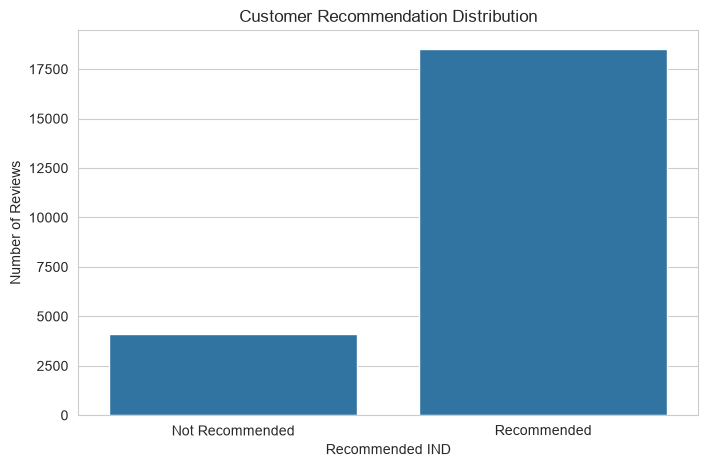

In [148]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Recommended IND'
)

plt.title("Customer Recommendation Distribution")
plt.xlabel("Recommended IND")
plt.ylabel("Number of Reviews")

plt.xticks(
    [0, 1],
    ['Not Recommended', 'Recommended']
)

plt.savefig(
    "outputs/recommended_distribution.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

## Calculate baseline accuracy

In [149]:
not_recommended_percentage = (
    df['Recommended IND'].eq(0).mean() * 100
)

baseline_accuracy = (
    df['Recommended IND'].eq(1).mean() * 100
)

print(
    f"Customers who do not recommend: "
    f"{not_recommended_percentage:.2f}%"
)

print(
    f"Always recommends baseline accuracy: "
    f"{baseline_accuracy:.2f}%"
)

Customers who do not recommend: 18.11%
Always recommends baseline accuracy: 81.89%


Explanation: The baseline always predicts class 1. It can achieve high accuracy because most reviews recommend the product, but it completely fails to identify unhappy customers.

## Department-wise not-recommended percentage

Department Name
Trend       25.423729
Dresses     19.479251
Tops        18.929140
Jackets     16.666667
Intimate    15.366001
Bottoms     15.046423
Name: Recommended IND, dtype: float64


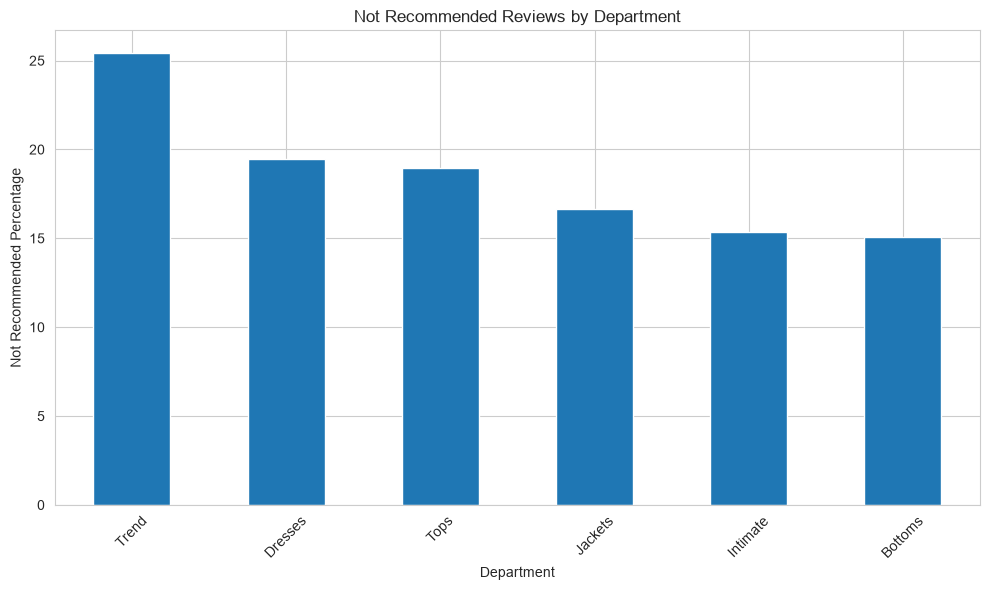

Department with highest complaint rate: Trend


In [150]:
department_analysis = (
    df.groupby('Department Name')['Recommended IND']
    .apply(lambda x: (x == 0).mean() * 100)
    .sort_values(ascending=False)
)

print(department_analysis)

plt.figure(figsize=(10, 6))

department_analysis.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title("Not Recommended Reviews by Department")
plt.xlabel("Department")
plt.ylabel("Not Recommended Percentage")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "outputs/department_analysis.png",
    dpi=300
)

plt.show()

print(
    "Department with highest complaint rate:",
    department_analysis.idxmax()
)

## Rating distribution

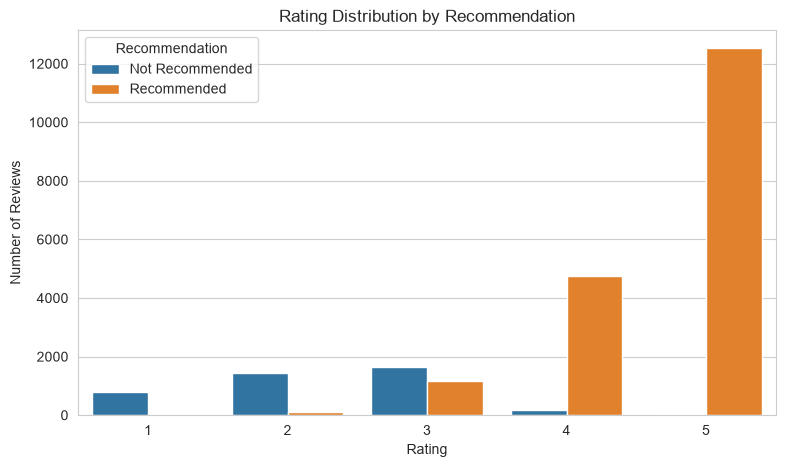

In [151]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='Rating',
    hue='Recommended IND'
)

plt.title("Rating Distribution by Recommendation")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")

plt.legend(
    title="Recommendation",
    labels=["Not Recommended", "Recommended"]
)

plt.savefig(
    "outputs/rating_distribution.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

## Find 4 and 5-star negative reviews

In [152]:
negative_high_rating = df[
    (df['Rating'].isin([4, 5])) &
    (df['Recommended IND'] == 0)
]

display(
    negative_high_rating[
        ['Title', 'Review Text', 'Rating']
    ].head(3)
)

,Title,Review Text,Rating
204,Too big,I loved this top; it reminded me of one i have...,4
440,Bunches up weirdly in the front,"I loved this dress as soon as i tried it on, b...",4
837,,"I ordered this in two colors, in my regular si...",4


Some customers give 4 or 5 stars but still do not recommend
the product. This can happen because customers have mixed
opinions, dislike the fitting, experience quality issues,
or have expectations that are not fully satisfied.

## Review length

In [153]:
df['review_length'] = (
    df['full_text'].apply(
        lambda text: len(text.split())
    )
)

display(
    df[['full_text', 'review_length']].head()
)

,full_text,review_length
0,Absolutely wonderful - silky and sexy and com...,8
1,Love this dress! it's sooo pretty. i happen...,62
2,Some major design flaws I had such high hopes ...,102
3,"My favorite buy! I love, love, love this jumps...",25
4,Flattering shirt This shirt is very flattering...,38


## Compare average review length

Average Review Length:
Recommended IND
0    65.211412
1    62.636785
Name: review_length, dtype: float64


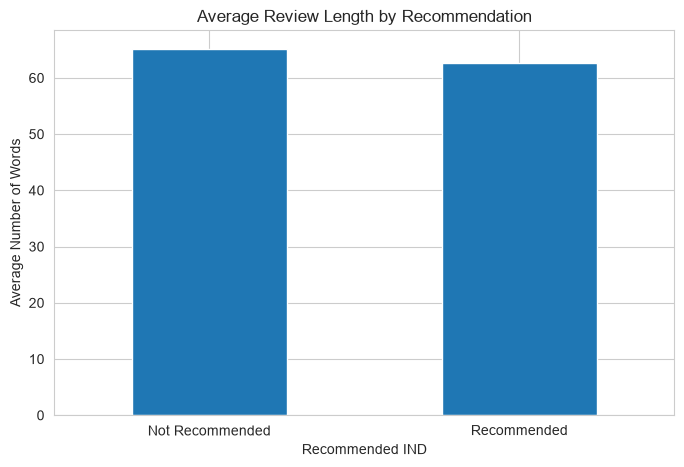

In [154]:
average_length = (
    df.groupby('Recommended IND')['review_length']
    .mean()
)

print("Average Review Length:")

print(average_length)

plt.figure(figsize=(8, 5))

average_length.plot(kind='bar')

plt.title("Average Review Length by Recommendation")
plt.xlabel("Recommended IND")
plt.ylabel("Average Number of Words")

plt.xticks(
    [0, 1],
    ['Not Recommended', 'Recommended'],
    rotation=0
)

plt.show()

## Split dataset

In [155]:
X = df['full_text']

y = df['Recommended IND']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Size:", X_train.shape)

print("Testing Size:", X_test.shape)

Training Size: (18112,)
Testing Size: (4529,)


## Check class percentages

In [156]:
print("Training Class Distribution:")

print(
    y_train.value_counts(normalize=True) * 100
)

print("\nTesting Class Distribution:")

print(
    y_test.value_counts(normalize=True) * 100
)

Training Class Distribution:
Recommended IND
1    81.884938
0    18.115062
Name: proportion, dtype: float64

Testing Class Distribution:
Recommended IND
1    81.894458
0    18.105542
Name: proportion, dtype: float64


## RegEx: Find size-related reviews

In [157]:
size_pattern = (
    r'(?i)\b(xxs|xs|small|medium|large|xl|xxl)\b'
)

size_reviews = X_train.str.contains(
    size_pattern,
    regex=True
)

size_count = size_reviews.sum()

size_negative_rate = (
    y_train[size_reviews].eq(0).mean() * 100
)

overall_negative_rate = (
    y_train.eq(0).mean() * 100
)

print("Size-related reviews:", size_count)

print(
    "Negative rate in size reviews:",
    round(size_negative_rate, 2), "%"
)

print(
    "Overall negative rate:",
    round(overall_negative_rate, 2), "%"
)

Size-related reviews: 6342
Negative rate in size reviews: 18.09 %
Overall negative rate: 18.12 %


## RegEx: Find height measurements

In [158]:
height_pattern = r"\b[4-6]['’]\s?\d{0,2}"

height_reviews = X_train[
    X_train.str.contains(
        height_pattern,
        regex=True
    )
]

print("Height-related reviews:")

for review in height_reviews.head(3):
    print("\n", review)

Height-related reviews:

 Perfect fall jacket Loved this from the minute i saw it in an email. i got the blue grey in a medium. i'm 5'4", 140. it's a little roomy but will be nice over sweaters too. i love the cropped length. really well made.

 In love I am 5'3 and tried this dress on in both a large and medium petite. the dress is supposed to be a lose fit but i found that i was swimming in the large but the medium was perfect. i bought it in a petite which is shorter for my comfort to wear alone but looks great with leggings and sandals for spring or with boots in the winter. the embroidery is beautiful plus it has pockets. first time i wore it i received tons of compliments.

 Beautiful and cozy This is a beautiful sweater/tunic/dress. i ordered in the mustard color, and wearing it will brighten my day on a dreary winter morning. it is so hard to find winter clothes in bright colors. the sweater is soft and not itchy. it is a bit longer than i expected...maybe 35" (i am 5'7"), but 

## Count exclamation marks

In [159]:
df['exclamation_count'] = (
    df['full_text'].apply(
        lambda text: len(re.findall(r'!', text))
    )
)

print(
    df.groupby('Recommended IND')['exclamation_count']
    .mean()
)

Recommended IND
0    0.411119
1    0.960086
Name: exclamation_count, dtype: float64


## Find ALL-CAPS words

In [160]:
df['capital_words'] = (
    df['full_text'].apply(
        lambda text: len(
            re.findall(r'\b[A-Z]{3,}\b', text)
        )
    )
)

print(
    df.groupby('Recommended IND')['capital_words']
    .mean()
)

Recommended IND
0    0.0
1    0.0
Name: capital_words, dtype: float64


## Replace numbers and expand contractions

In [161]:
def regex_cleaning(text):

    text = re.sub(
        r"\b(\w+)n't\b",
        r"\1 not",
        text,
        flags=re.IGNORECASE
    )

    text = re.sub(
        r'\d+',
        'NUM',
        text
    )

    return text


for review in X_train.head(3):

    print("\nORIGINAL:")
    print(review)

    print("\nCLEANED:")
    print(regex_cleaning(review))

    print("-" * 60)


ORIGINAL:
Perfect fall jacket Loved this from the minute i saw it in an email. i got the blue grey in a medium. i'm 5'4", 140. it's a little roomy but will be nice over sweaters too. i love the cropped length. really well made.

CLEANED:
Perfect fall jacket Loved this from the minute i saw it in an email. i got the blue grey in a medium. i'm NUM'NUM", NUM. it's a little roomy but will be nice over sweaters too. i love the cropped length. really well made.
------------------------------------------------------------

ORIGINAL:
Going back... I purchased this dress in the green, and while the print and material were lovely, the extra folds in the neckline made the dress look frumpy up top. the billowly bottom made it look like a bag. i am 5ft, 36d and 29" waist and the size 2 fit, which makes me think this runs large! i'll be returning this dress.

CLEANED:
Going back... I purchased this dress in the green, and while the print and material were lovely, the extra folds in the neckline mad

## Import preprocessing libraries

In [162]:
import nltk

from nltk.tokenize import word_tokenize

from nltk.corpus import stopwords

from nltk.stem import WordNetLemmatizer

from nltk.stem import PorterStemmer

stop_words = set(stopwords.words('english'))

# Preserve negative meaning
stop_words = stop_words - {'not', 'no', 'nor'}

lemmatizer = WordNetLemmatizer()

print("Text preprocessing libraries ready!")

Text preprocessing libraries ready!


## Create clean_text function

In [163]:
def clean_text(text):

    if pd.isna(text):
        return ""

    text = str(text).lower()

    # Expand n't contractions
    text = re.sub(
        r"n't\b",
        " not",
        text
    )

    # Remove everything except letters and spaces
    text = re.sub(
        r'[^a-zA-Z\s]',
        ' ',
        text
    )

    # Tokenization
    tokens = word_tokenize(text)

    # Remove stopwords
    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    # Lemmatization
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    # Join tokens
    cleaned_text = ' '.join(tokens)

    return cleaned_text

## Apply text cleaning

In [164]:
X_train_clean = X_train.apply(clean_text)

X_test_clean = X_test.apply(clean_text)

print("Training text cleaned!")

print("Testing text cleaned!")

Training text cleaned!
Testing text cleaned!


## Compare original and cleaned reviews

In [165]:
comparison = pd.DataFrame({
    'Original Text': X_train.head(5),
    'Cleaned Text': X_train_clean.head(5)
})

display(comparison)

,Original Text,Cleaned Text
16998,Perfect fall jacket Loved this from the minute...,perfect fall jacket loved minute saw email got...
18766,Going back... I purchased this dress in the gr...,going back purchased dress green print materia...
2670,Love these but color faded when washed I'm pre...,love color faded washed pretty disappointed bo...
7547,Great staple! I ordered this a little big beca...,great staple ordered little big smallest size ...
7786,Crazy soft and comfy. light weight so will b...,crazy soft comfy light weight great spring sum...


## Stemming versus Lemmatization

In [166]:
words = [
    'fitting',
    'fitted',
    'dresses',
    'flattering',
    'shrunk',
    'returned',
    'wearing',
    'better'
]

porter = PorterStemmer()

lemmatizer = WordNetLemmatizer()

results = []

for word in words:

    results.append({
        'Original Word': word,
        'Porter Stem': porter.stem(word),
        'WordNet Lemma': lemmatizer.lemmatize(word)
    })

stemming_table = pd.DataFrame(results)

display(stemming_table)

,Original Word,Porter Stem,WordNet Lemma
0,fitting,fit,fitting
1,fitted,fit,fitted
2,dresses,dress,dress
3,flattering,flatter,flattering
4,shrunk,shrunk,shrunk
5,returned,return,returned
6,wearing,wear,wearing
7,better,better,better


### Stemming vs Lemmatization

Stemming removes word endings using simple rules.
It may produce words that are not grammatically correct.

Lemmatization converts words into their meaningful dictionary
form.

Lemmatization can use part-of-speech information to produce
more accurate results. Without POS information, the default
WordNet lemmatizer generally treats words as nouns.

## Word frequency analysis

In [167]:
negative_text = X_train_clean[
    y_train == 0
]

positive_text = X_train_clean[
    y_train == 1
]

negative_words = Counter(
    ' '.join(negative_text).split()
)

positive_words = Counter(
    ' '.join(positive_text).split()
)

print("Top 15 Negative Review Words:")

print(negative_words.most_common(15))

print("\nTop 15 Positive Review Words:")

print(positive_words.most_common(15))

Top 15 Negative Review Words:
[('not', 4078), ('dress', 1812), ('like', 1493), ('top', 1475), ('fit', 1364), ('look', 1305), ('would', 1164), ('fabric', 1089), ('size', 1077), ('color', 871), ('back', 870), ('love', 847), ('small', 812), ('really', 722), ('ordered', 666)]

Top 15 Positive Review Words:
[('not', 11321), ('dress', 8646), ('love', 7882), ('fit', 7350), ('size', 6670), ('top', 6197), ('great', 5762), ('color', 5108), ('wear', 4718), ('like', 4360), ('look', 4324), ('perfect', 3523), ('small', 3305), ('would', 3164), ('cute', 3138)]


## Plot word frequencies

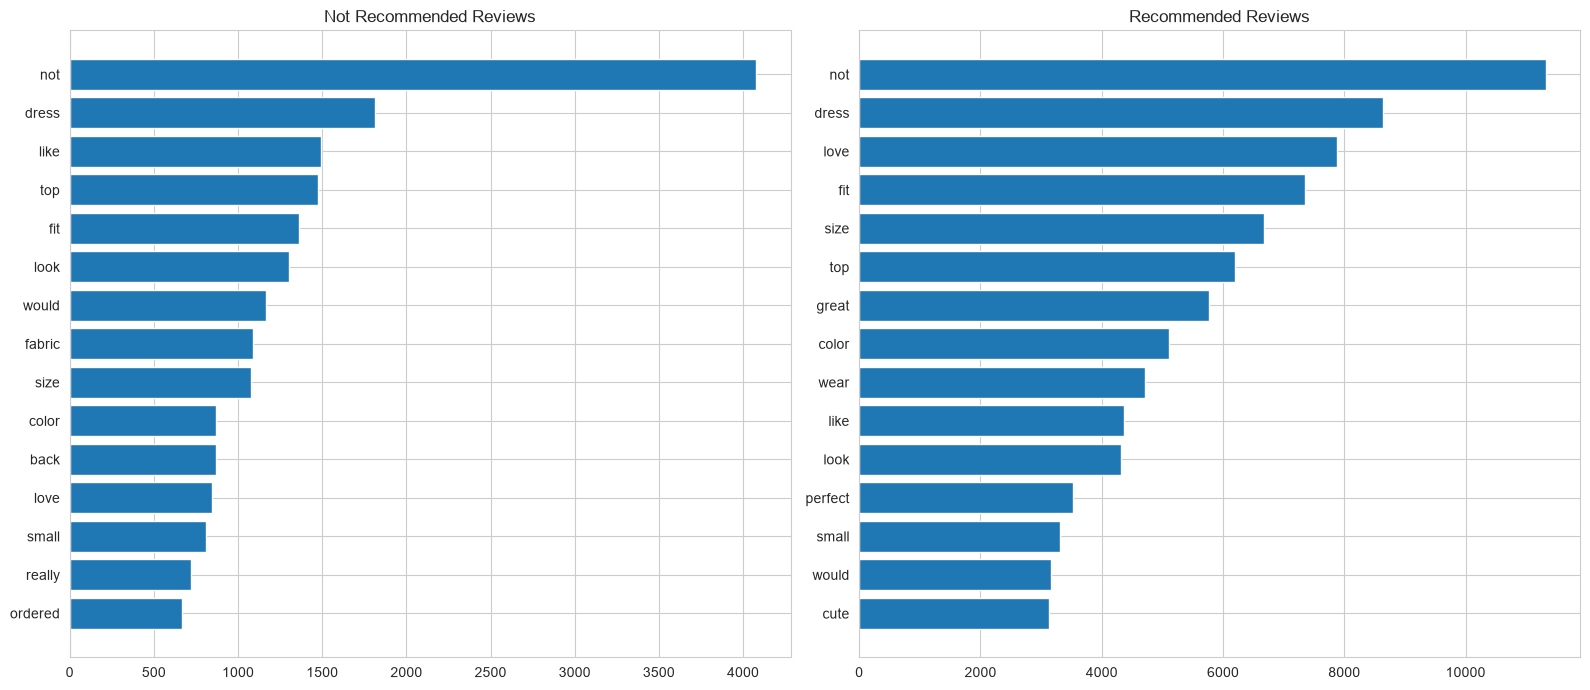

In [168]:
negative_top = negative_words.most_common(15)

positive_top = positive_words.most_common(15)

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7)
)

axes[0].barh(
    [x[0] for x in negative_top][::-1],
    [x[1] for x in negative_top][::-1]
)

axes[0].set_title("Not Recommended Reviews")

axes[1].barh(
    [x[0] for x in positive_top][::-1],
    [x[1] for x in positive_top][::-1]
)

axes[1].set_title("Recommended Reviews")

plt.tight_layout()

plt.savefig(
    "outputs/word_frequency.png",
    dpi=300
)

plt.show()

# Step 2 — Feature Extraction
## 2.1 Bag-of-Words (BoW) on Tiny Corpus
## Create tiny fashion review dataset

In [169]:
documents = [
    "love this dress fits perfectly",
    "dress runs small and fits poorly",
    "great quality great fit",
    "not worth the price"
]

print("Total Documents:", len(documents))

for i, doc in enumerate(documents, 1):
    print(f"Document {i}: {doc}")

Total Documents: 4
Document 1: love this dress fits perfectly
Document 2: dress runs small and fits poorly
Document 3: great quality great fit
Document 4: not worth the price


## Apply CountVectorizer

In [170]:
from sklearn.feature_extraction.text import CountVectorizer

count_vectorizer = CountVectorizer()

bow_matrix = count_vectorizer.fit_transform(documents)

print("Vocabulary:")

print(count_vectorizer.get_feature_names_out())

Vocabulary:
['and' 'dress' 'fit' 'fits' 'great' 'love' 'not' 'perfectly' 'poorly'
 'price' 'quality' 'runs' 'small' 'the' 'this' 'worth']


## Convert BoW into DataFrame

In [171]:
bow_df = pd.DataFrame(
    bow_matrix.toarray(),
    columns=count_vectorizer.get_feature_names_out(),
    index=[
        'Doc 1',
        'Doc 2',
        'Doc 3',
        'Doc 4'
    ]
)

display(bow_df)

,and,dress,fit,fits,great,love,not,perfectly,poorly,price,quality,runs,small,the,this,worth
Doc 1,0,1,0,1,0,1,0,1,0,0,0,0,0,0,1,0
Doc 2,1,1,0,1,0,0,0,0,1,0,0,1,1,0,0,0
Doc 3,0,0,1,0,2,0,0,0,0,0,1,0,0,0,0,0
Doc 4,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0,1


# 2.2 TF-IDF on Tiny Corpus
## Apply TF-IDF

In [172]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer()

tfidf_matrix = tfidf_vectorizer.fit_transform(documents)

tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf_vectorizer.get_feature_names_out(),
    index=[
        'Doc 1',
        'Doc 2',
        'Doc 3',
        'Doc 4'
    ]
)

display(tfidf_df.round(2))

,and,dress,fit,fits,great,love,not,perfectly,poorly,price,quality,runs,small,the,this,worth
Doc 1,0.00,0.38,0.00,0.38,0.00,0.49,0.0,0.49,0.00,0.0,0.00,0.00,0.00,0.0,0.49,0.0
Doc 2,0.44,0.34,0.00,0.34,0.00,0.00,0.0,0.00,0.44,0.0,0.00,0.44,0.44,0.0,0.00,0.0
Doc 3,0.00,0.00,0.41,0.00,0.82,0.00,0.0,0.00,0.00,0.0,0.41,0.00,0.00,0.0,0.00,0.0
Doc 4,0.00,0.00,0.00,0.00,0.00,0.00,0.5,0.00,0.00,0.5,0.00,0.00,0.00,0.5,0.00,0.5


## Compare TF-IDF word weights

In [173]:
print("Dress TF-IDF Scores:")

print(tfidf_df['dress'])

print("\nQuality TF-IDF Scores:")

print(tfidf_df['quality'])

print("\nAverage TF-IDF:")

print(
    "Dress:",
    tfidf_df['dress'].mean()
)

print(
    "Quality:",
    tfidf_df['quality'].mean()
)

Dress TF-IDF Scores:
Doc 1    0.382743
Doc 2    0.344315
Doc 3    0.000000
Doc 4    0.000000
Name: dress, dtype: float64

Quality TF-IDF Scores:
Doc 1    0.000000
Doc 2    0.000000
Doc 3    0.408248
Doc 4    0.000000
Name: quality, dtype: float64

Average TF-IDF:
Dress: 0.1817643106339052
Quality: 0.10206207261596575


### TF-IDF Explanation

TF (Term Frequency):
Measures how frequently a word appears in a document.

IDF (Inverse Document Frequency):
Measures how important a word is across all documents.

TF-IDF:
Combines term frequency and inverse document frequency.

Formula:

TF-IDF = TF × IDF

Common words generally receive lower IDF scores.
Words that are more distinctive across documents can
receive higher IDF scores.

# 2.3 N-Grams
## Extract bigrams

In [174]:
bigram_vectorizer = CountVectorizer(
    ngram_range=(2, 2)
)

bigram_matrix = bigram_vectorizer.fit_transform(
    documents
)

print("All Bigrams:")

print(
    bigram_vectorizer.get_feature_names_out()
)

All Bigrams:
['and fits' 'dress fits' 'dress runs' 'fits perfectly' 'fits poorly'
 'great fit' 'great quality' 'love this' 'not worth' 'quality great'
 'runs small' 'small and' 'the price' 'this dress' 'worth the']


## Unigrams and bigrams together

In [175]:
ngram_vectorizer = CountVectorizer(
    ngram_range=(1, 2)
)

ngram_matrix = ngram_vectorizer.fit_transform(
    documents
)

ngram_df = pd.DataFrame(
    ngram_matrix.toarray(),
    columns=ngram_vectorizer.get_feature_names_out()
)

display(ngram_df)

,and,and fits,dress,dress fits,dress runs,fit,fits,fits perfectly,fits poorly,great,...,runs,runs small,small,small and,the,the price,this,this dress,worth,worth the
0,0,0,1,1,0,0,1,1,0,0,...,0,0,0,0,0,0,1,1,0,0
1,1,1,1,0,1,0,1,0,1,0,...,1,1,1,1,0,0,0,0,0,0
2,0,0,0,0,0,1,0,0,0,2,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,1,0,0,1,1


## Find meaningful bigrams

In [176]:
doc4_vectorizer = CountVectorizer(
    ngram_range=(2, 2)
)

doc4_matrix = doc4_vectorizer.fit_transform(
    [documents[3]]
)

print("Doc 4 Bigrams:")

print(
    doc4_vectorizer.get_feature_names_out()
)

Doc 4 Bigrams:
['not worth' 'the price' 'worth the']


Explanation:

The phrase not worth captures the negative meaning of the fourth review. The individual word worth does not communicate the same meaning because it ignores the negation.

# 2.4 Features on Real Reviews
# Bag-of-Words on training reviews

In [177]:
bow_real_vectorizer = CountVectorizer(
    max_features=5000
)

X_train_bow = bow_real_vectorizer.fit_transform(
    X_train_clean
)

X_test_bow = bow_real_vectorizer.transform(
    X_test_clean
)

print("Training Matrix Shape:", X_train_bow.shape)

print("Testing Matrix Shape:", X_test_bow.shape)

Training Matrix Shape: (18112, 5000)
Testing Matrix Shape: (4529, 5000)


## Calculate BoW sparsity

In [178]:
total_elements = (
    X_train_bow.shape[0] *
    X_train_bow.shape[1]
)

zero_elements = (
    total_elements - X_train_bow.count_nonzero()
)

bow_sparsity = (
    zero_elements / total_elements
) * 100

print(
    "BoW Sparsity:",
    round(bow_sparsity, 2),
    "%"
)

BoW Sparsity: 99.46 %


## TF-IDF on training reviews

In [179]:
tfidf_real_vectorizer = TfidfVectorizer(
    max_features=5000
)

X_train_tfidf = tfidf_real_vectorizer.fit_transform(
    X_train_clean
)

X_test_tfidf = tfidf_real_vectorizer.transform(
    X_test_clean
)

print("Training TF-IDF Shape:", X_train_tfidf.shape)

print("Testing TF-IDF Shape:", X_test_tfidf.shape)

Training TF-IDF Shape: (18112, 5000)
Testing TF-IDF Shape: (4529, 5000)


## Find top 10 TF-IDF words

In [180]:
average_tfidf = np.asarray(
    X_train_tfidf.mean(axis=0)
).ravel()

feature_names = (
    tfidf_real_vectorizer.get_feature_names_out()
)

tfidf_word_scores = pd.DataFrame({
    'Word': feature_names,
    'Average TF-IDF': average_tfidf
})

tfidf_word_scores = tfidf_word_scores.sort_values(
    by='Average TF-IDF',
    ascending=False
)

display(tfidf_word_scores.head(10))

,Word,Average TF-IDF
1284,dress,0.049638
2822,not,0.049581
2472,love,0.041433
4469,top,0.038637
1609,fit,0.037263
1886,great,0.034852
3875,size,0.034713
837,color,0.029680
2443,look,0.027439
2392,like,0.027259


## Extract negative review bigrams

In [181]:
negative_train_text = X_train_clean[
    y_train == 0
]

negative_bigram_vectorizer = CountVectorizer(
    ngram_range=(2, 2),
    max_features=3000
)

negative_bigram_matrix = (
    negative_bigram_vectorizer.fit_transform(
        negative_train_text
    )
)

bigram_counts = np.asarray(
    negative_bigram_matrix.sum(axis=0)
).ravel()

bigram_names = (
    negative_bigram_vectorizer.get_feature_names_out()
)

negative_bigram_results = pd.DataFrame({
    'Bigram': bigram_names,
    'Frequency': bigram_counts
})

negative_bigram_results = (
    negative_bigram_results
    .sort_values(
        by='Frequency',
        ascending=False
    )
)

print("Top 10 Negative Review Bigrams:")

display(negative_bigram_results.head(10))

Top 10 Negative Review Bigrams:


,Bigram,Frequency
2817,wanted love,268
1290,look like,235
1679,not flattering,232
390,could not,192
1802,not work,191
901,going back,185
1328,looked like,161
2976,would not,143
290,ca not,138
2104,really wanted,133


Explanation: These bigrams help identify common customer complaints, such as problems with fitting, fabric quality, product size and comfort.

## Calculate bigram sparsity

In [182]:
total_elements = (
    negative_bigram_matrix.shape[0] *
    negative_bigram_matrix.shape[1]
)

zero_elements = (
    total_elements -
    negative_bigram_matrix.count_nonzero()
)

bigram_sparsity = (
    zero_elements / total_elements
) * 100

print(
    "Negative Bigram Sparsity:",
    round(bigram_sparsity, 2),
    "%"
)

Negative Bigram Sparsity: 99.69 %


## Create feature comparison table

In [183]:
def calculate_sparsity(matrix):

    total = matrix.shape[0] * matrix.shape[1]

    non_zero = matrix.count_nonzero()

    zeros = total - non_zero

    return (zeros / total) * 100


feature_comparison = pd.DataFrame({

    'Method': [
        'Bag of Words',
        'TF-IDF',
        'Negative Review Bigrams'
    ],

    'Number of Features': [
        X_train_bow.shape[1],
        X_train_tfidf.shape[1],
        negative_bigram_matrix.shape[1]
    ],

    'Sparsity %': [
        calculate_sparsity(X_train_bow),
        calculate_sparsity(X_train_tfidf),
        calculate_sparsity(negative_bigram_matrix)
    ]

})

display(feature_comparison.round(2))

,Method,Number of Features,Sparsity %
0,Bag of Words,5000,99.46
1,TF-IDF,5000,99.46
2,Negative Review Bigrams,3000,99.69


# Step 2 – Reflection

1. Bag-of-Words represents text using word frequency.
   It is simple but ignores word order and context.

2. TF-IDF gives more importance to words that are
   distinctive across documents.

3. N-Grams capture combinations of words and help
   understand phrases such as "not worth" and
   "poor quality".

4. Test reviews must have the same feature columns
   as training reviews because the model expects
   a consistent input structure.

5. A word that was never seen during training is
   generally ignored by the fitted vectorizer.

# Step 3 — Word Embeddings: Word2Vec
## 3.1 Prepare Tokens
## Import Word2Vec

In [184]:
from gensim.models import Word2Vec

print("Word2Vec imported successfully!")

Word2Vec imported successfully!


## Create tokens column

In [185]:
tokens = X_train_clean.apply(
    lambda text: text.split()
).tolist()

print("First 5 Tokenized Reviews:")

for token in tokens[:5]:
    print(token)

First 5 Tokenized Reviews:
['perfect', 'fall', 'jacket', 'loved', 'minute', 'saw', 'email', 'got', 'blue', 'grey', 'medium', 'little', 'roomy', 'nice', 'sweater', 'love', 'cropped', 'length', 'really', 'well', 'made']
['going', 'back', 'purchased', 'dress', 'green', 'print', 'material', 'lovely', 'extra', 'fold', 'neckline', 'made', 'dress', 'look', 'frumpy', 'top', 'billowly', 'bottom', 'made', 'look', 'like', 'bag', 'ft', 'waist', 'size', 'fit', 'make', 'think', 'run', 'large', 'returning', 'dress']
['love', 'color', 'faded', 'washed', 'pretty', 'disappointed', 'bought', 'yellow', 'pair', 'wore', 'today', 'first', 'time', 'super', 'cute', 'comfortable', 'love', 'got', 'two', 'small', 'stain', 'day', 'activity', 'not', 'even', 'crazy', 'untreatable', 'stain', 'unfortunately', 'stain', 'not', 'budge', 'yet', 'color', 'short', 'washed', 'completely', 'ruined', 'one', 'washing', 'cold', 'hoping', 'fluke', 'plan', 'order', 'second', 'pair', 'sell', 'going', 'back']
['great', 'staple', 'or

## Calculate average tokens

In [186]:
average_tokens = np.mean([
    len(sentence)
    for sentence in tokens
])

print(
    "Average Tokens Per Review:",
    round(average_tokens, 2)
)

Average Tokens Per Review: 31.25


## Calculate unique vocabulary

In [187]:
all_words = [
    word
    for sentence in tokens
    for word in sentence
]

unique_words = set(all_words)

print("Total Words:", len(all_words))

print("Unique Words:", len(unique_words))

Total Words: 565924
Unique Words: 11497


# 3.2 Train CBoW and Skip-gram Models
## Train CBoW model

In [188]:
cbow_model = Word2Vec(

    sentences=tokens,

    vector_size=100,

    window=5,

    min_count=5,

    sg=0,

    epochs=10,

    seed=42,

    workers=1

)

print("CBoW model trained successfully!")

CBoW model trained successfully!


## Train Skip-gram model

In [189]:
skipgram_model = Word2Vec(

    sentences=tokens,

    vector_size=100,

    window=5,

    min_count=5,

    sg=1,

    epochs=10,

    seed=42,

    workers=1

)

print("Skip-gram model trained successfully!")

Skip-gram model trained successfully!


## Compare vocabulary sizes

In [190]:
print(
    "CBoW Vocabulary Size:",
    len(cbow_model.wv)
)

print(
    "Skip-gram Vocabulary Size:",
    len(skipgram_model.wv)
)

CBoW Vocabulary Size: 3910
Skip-gram Vocabulary Size: 3910


## Check dress word vectors

In [191]:
word = 'dress'

if word in cbow_model.wv:

    print(
        "CBoW Vector Shape:",
        cbow_model.wv[word].shape
    )

if word in skipgram_model.wv:

    print(
        "Skip-gram Vector Shape:",
        skipgram_model.wv[word].shape
    )

CBoW Vector Shape: (100,)
Skip-gram Vector Shape: (100,)


# 3.3 Explore Word Embeddings
## Find similar words

In [192]:
query_words = [
    'dress',
    'small',
    'comfortable',
    'cheap',
    'return'
]


def get_similar_words(model, word):

    if word in model.wv:

        return model.wv.most_similar(
            word,
            topn=5
        )

    else:

        return f"'{word}' not found in vocabulary"


for word in query_words:

    print("\nWord:", word)

    print("\nCBoW:")

    print(
        get_similar_words(
            cbow_model,
            word
        )
    )

    print("\nSkip-gram:")

    print(
        get_similar_words(
            skipgram_model,
            word
        )
    )

    print("-" * 60)


Word: dress

CBoW:
[('wedding', 0.5116645693778992), ('maxi', 0.49782368540763855), ('beyond', 0.4346526265144348), ('brother', 0.4317164719104767), ('occasion', 0.4021381437778473)]

Skip-gram:
[('elegantly', 0.6741390228271484), ('bridesmaid', 0.6468596458435059), ('gorgeously', 0.6445654034614563), ('carefree', 0.6411142349243164), ('smitten', 0.6405143141746521)]
------------------------------------------------------------

Word: small

CBoW:
[('large', 0.8838995099067688), ('big', 0.7231906056404114), ('l', 0.7175235152244568), ('x', 0.7007248401641846), ('medium', 0.6989654898643494)]

Skip-gram:
[('large', 0.861014187335968), ('xsmall', 0.7721139192581177), ('petit', 0.7592055201530457), ('swam', 0.7533222436904907), ('medium', 0.7420775294303894)]
------------------------------------------------------------

Word: comfortable

CBoW:
[('comfy', 0.8051788806915283), ('wonderfully', 0.5257928967475891), ('relaxed', 0.5120729804039001), ('stretchy', 0.44782814383506775), ('awesome

## Compare word similarities

In [193]:
word_pairs = [
    ('small', 'tight'),
    ('large', 'loose'),
    ('soft', 'comfortable'),
    ('love', 'hate')
]


similarity_results = []

for word1, word2 in word_pairs:

    if (
        word1 in cbow_model.wv and
        word2 in cbow_model.wv
    ):

        cbow_similarity = (
            cbow_model.wv.similarity(
                word1,
                word2
            )
        )

    else:

        cbow_similarity = np.nan


    if (
        word1 in skipgram_model.wv and
        word2 in skipgram_model.wv
    ):

        skipgram_similarity = (
            skipgram_model.wv.similarity(
                word1,
                word2
            )
        )

    else:

        skipgram_similarity = np.nan


    similarity_results.append({

        'Word Pair': f'{word1} - {word2}',

        'CBoW Similarity': cbow_similarity,

        'Skip-gram Similarity': skipgram_similarity

    })


similarity_df = pd.DataFrame(
    similarity_results
)

display(similarity_df.round(4))

,Word Pair,CBoW Similarity,Skip-gram Similarity
0,small - tight,0.5637,0.5125
1,large - loose,0.3777,0.4506
2,soft - comfortable,0.3621,0.5599
3,love - hate,0.0415,0.4178


## Create CBoW vs Skip-gram comparison table

In [194]:
comparison_results = []

for word in query_words:

    cbow_words = get_similar_words(
        cbow_model,
        word
    )

    skipgram_words = get_similar_words(
        skipgram_model,
        word
    )


    if isinstance(cbow_words, list):

        cbow_top3 = [
            item[0]
            for item in cbow_words[:3]
        ]

    else:

        cbow_top3 = cbow_words


    if isinstance(skipgram_words, list):

        skipgram_top3 = [
            item[0]
            for item in skipgram_words[:3]
        ]

    else:

        skipgram_top3 = skipgram_words


    comparison_results.append({

        'Query Word': word,

        'Top-3 CBoW': cbow_top3,

        'Top-3 Skip-gram': skipgram_top3

    })


word_comparison_df = pd.DataFrame(
    comparison_results
)

display(word_comparison_df)

,Query Word,Top-3 CBoW,Top-3 Skip-gram
0,dress,"[wedding, maxi, beyond]","[elegantly, bridesmaid, gorgeously]"
1,small,"[large, big, l]","[large, xsmall, petit]"
2,comfortable,"[comfy, wonderfully, relaxed]","[comfy, uber, flexible]"
3,cheap,"[flimsy, awful, shiny]","[blah, shiny, synthetic]"
4,return,"[exchange, returning, returned]","[exchange, returned, returning]"


### CBoW vs Skip-gram

CBoW predicts a target word from its surrounding context.
Skip-gram predicts surrounding words from a target word.

Skip-gram can often learn useful representations for
less frequent words because it generates multiple
context prediction examples.

The quality of both models depends on the size and
quality of the training dataset.

# 3.4 Visualize Word2Vec using PCA
## Select 25 fashion-related words

In [195]:
fit_words = [
    'small', 'large', 'tight', 'loose',
    'short', 'long', 'snug', 'baggy'
]

quality_words = [
    'fabric', 'material', 'soft',
    'cheap', 'thin', 'stitching',
    'color', 'lining', 'wrinkle'
]

emotion_words = [
    'love', 'beautiful', 'gorgeous',
    'disappointed', 'ugly', 'regret',
    'perfect', 'flattering'
]

selected_words = (
    fit_words +
    quality_words +
    emotion_words
)

print("Total Selected Words:", len(selected_words))

Total Selected Words: 25


## Filter words available in vocabulary

In [196]:
available_words = [
    word
    for word in selected_words
    if word in skipgram_model.wv
]

missing_words = [
    word
    for word in selected_words
    if word not in skipgram_model.wv
]

print("Available Words:", len(available_words))

print("Missing Words:", missing_words)

Available Words: 25
Missing Words: []


## Apply PCA and plot

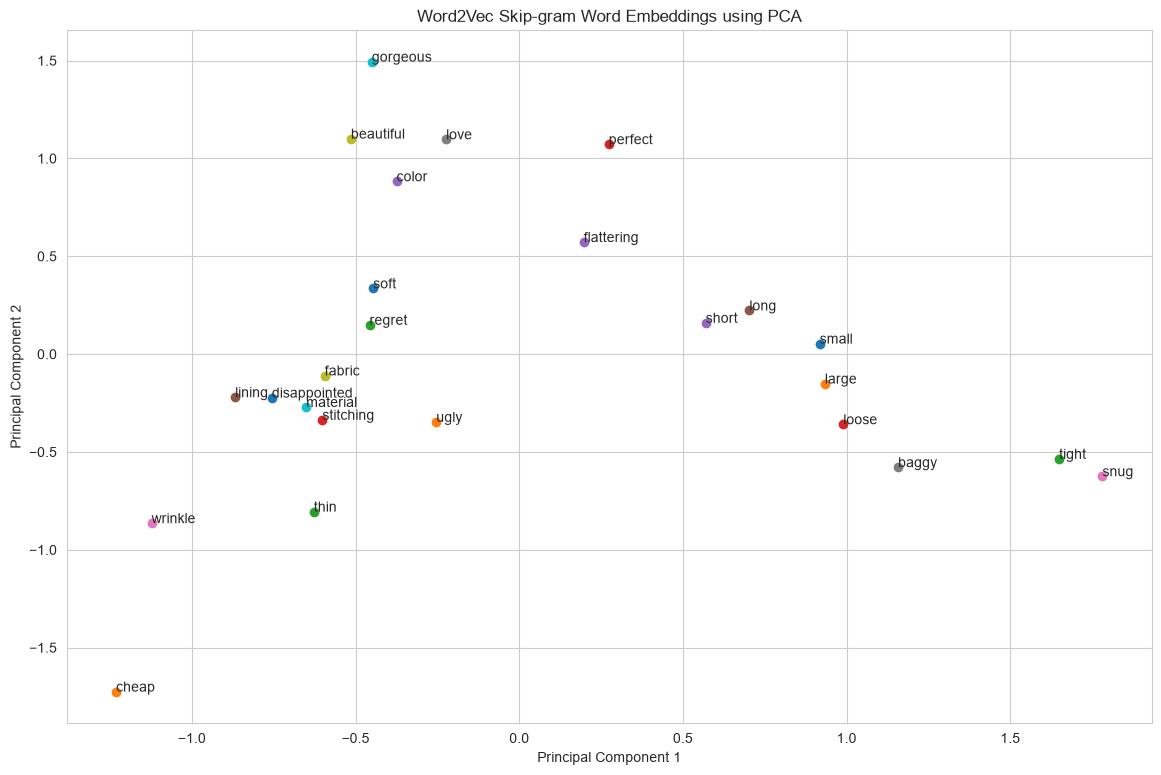

In [197]:
from sklearn.decomposition import PCA

if len(available_words) >= 2:

    word_vectors = np.array([
        skipgram_model.wv[word]
        for word in available_words
    ])

    pca = PCA(n_components=2)

    reduced_vectors = pca.fit_transform(
        word_vectors
    )

    pca_df = pd.DataFrame({

        'Word': available_words,

        'PC1': reduced_vectors[:, 0],

        'PC2': reduced_vectors[:, 1]

    })

    plt.figure(figsize=(14, 9))

    for _, row in pca_df.iterrows():

        plt.scatter(
            row['PC1'],
            row['PC2']
        )

        plt.annotate(
            row['Word'],
            (row['PC1'], row['PC2']),
            fontsize=10
        )

    plt.title(
        "Word2Vec Skip-gram Word Embeddings using PCA"
    )

    plt.xlabel("Principal Component 1")

    plt.ylabel("Principal Component 2")

    plt.grid(True)

    plt.savefig(
        "outputs/word2vec_pca.png",
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()

else:

    print("Not enough available words for PCA.")

PCA stands for Principal Component Analysis. Word2Vec generates 100-dimensional word vectors. PCA reduces these vectors to two dimensions so that we can visualize relationships between words on a scatter plot.

# 3.5 Save Word2Vec Model
## Save Skip-gram model

In [198]:
skipgram_model.save(
    'word2vec_skipgram.model'
)

print("Skip-gram model saved successfully!")

Skip-gram model saved successfully!


## Load and test saved model

In [199]:
from gensim.models import Word2Vec

loaded_w2v_model = Word2Vec.load(
    'word2vec_skipgram.model'
)

print("Saved model loaded successfully!")

print(
    loaded_w2v_model.wv.most_similar(
        'dress',
        topn=5
    )
)

Saved model loaded successfully!
[('elegantly', 0.6741390228271484), ('bridesmaid', 0.6468596458435059), ('gorgeously', 0.6445654034614563), ('carefree', 0.6411142349243164), ('smitten', 0.6405143141746521)]


# Step 3 – Word Embeddings Reflection

### 1. What is Word2Vec?

Word2Vec is a word embedding technique that converts
words into dense numerical vectors.

### 2. CBoW

CBoW predicts the target word using surrounding words.

### 3. Skip-gram

Skip-gram predicts surrounding context words using
the target word.

### 4. Which is better for rare words?

Skip-gram can be more useful for rare words because
it learns by predicting context words from each
target word.

### 5. Why are dense vectors useful?

A dense 100-dimensional vector can represent
relationships and similarities between words.

Unlike Bag-of-Words, Word2Vec can learn semantic
relationships between words.

# Step 4 — Model Training and Evaluation
## Import model evaluation libraries

In [200]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import joblib
import os

print("Model evaluation libraries imported successfully!")

Model evaluation libraries imported successfully!


## Create the baseline model

In [201]:
baseline_predictions = np.ones(len(y_test), dtype=int)

baseline_accuracy = accuracy_score(y_test, baseline_predictions)

baseline_precision = precision_score(
    y_test,
    baseline_predictions,
    pos_label=0,
    zero_division=0
)

baseline_recall = recall_score(
    y_test,
    baseline_predictions,
    pos_label=0,
    zero_division=0
)

baseline_f1 = f1_score(
    y_test,
    baseline_predictions,
    pos_label=0,
    zero_division=0
)

print("BASELINE MODEL RESULTS")
print("----------------------")
print("Accuracy:", round(baseline_accuracy, 4))
print("Class 0 Precision:", round(baseline_precision, 4))
print("Class 0 Recall:", round(baseline_recall, 4))
print("Class 0 F1-score:", round(baseline_f1, 4))

BASELINE MODEL RESULTS
----------------------
Accuracy: 0.8189
Class 0 Precision: 0.0
Class 0 Recall: 0.0
Class 0 F1-score: 0.0


## Define the Logistic Regression model

In [202]:
def create_logistic_regression():
    return LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )

## Model A: Bag of Words + Logistic Regression

In [203]:
bow_pipeline = Pipeline([
    (
        "vectorizer",
        CountVectorizer(max_features=5000)
    ),
    (
        "classifier",
        create_logistic_regression()
    )
])

bow_pipeline.fit(X_train_clean, y_train)

bow_predictions = bow_pipeline.predict(X_test_clean)

bow_probabilities = bow_pipeline.predict_proba(X_test_clean)[:, 1]

print("Bag of Words model trained successfully!")

Bag of Words model trained successfully!


## Model B: TF-IDF + Logistic Regression

In [204]:
tfidf_pipeline = Pipeline([
    (
        "vectorizer",
        TfidfVectorizer(max_features=5000)
    ),
    (
        "classifier",
        create_logistic_regression()
    )
])

tfidf_pipeline.fit(X_train_clean, y_train)

tfidf_predictions = tfidf_pipeline.predict(X_test_clean)

tfidf_probabilities = tfidf_pipeline.predict_proba(X_test_clean)[:, 1]

print("TF-IDF model trained successfully!")

TF-IDF model trained successfully!


## Model C: TF-IDF Unigrams + Bigrams

In [205]:
tfidf_bigram_pipeline = Pipeline([
    (
        "vectorizer",
        TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2)
        )
    ),
    (
        "classifier",
        create_logistic_regression()
    )
])

tfidf_bigram_pipeline.fit(X_train_clean, y_train)

bigram_predictions = tfidf_bigram_pipeline.predict(X_test_clean)

bigram_probabilities = tfidf_bigram_pipeline.predict_proba(X_test_clean)[:, 1]

print("TF-IDF Unigram + Bigram model trained successfully!")

TF-IDF Unigram + Bigram model trained successfully!


## Create Word2Vec average document vectors

In [206]:
def get_average_word2vec(text, model):
    words = text.split()

    vectors = [
        model.wv[word]
        for word in words
        if word in model.wv
    ]

    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)


X_train_w2v = np.array([
    get_average_word2vec(text, skipgram_model)
    for text in X_train_clean
])

X_test_w2v = np.array([
    get_average_word2vec(text, skipgram_model)
    for text in X_test_clean
])

print("Training Word2Vec shape:", X_train_w2v.shape)
print("Testing Word2Vec shape:", X_test_w2v.shape)

Training Word2Vec shape: (18112, 100)
Testing Word2Vec shape: (4529, 100)


## Model D: Word2Vec + Logistic Regression

In [207]:
w2v_classifier = create_logistic_regression()

w2v_classifier.fit(X_train_w2v, y_train)

w2v_predictions = w2v_classifier.predict(X_test_w2v)

w2v_probabilities = w2v_classifier.predict_proba(X_test_w2v)[:, 1]

print("Word2Vec + Logistic Regression model trained successfully!")

Word2Vec + Logistic Regression model trained successfully!


## Create a model evaluation function

In [208]:
def evaluate_model(model_name, y_true, predictions, probabilities):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Class 0 Precision": precision_score(
            y_true, predictions, pos_label=0, zero_division=0
        ),
        "Class 0 Recall": recall_score(
            y_true, predictions, pos_label=0, zero_division=0
        ),
        "Class 0 F1": f1_score(
            y_true, predictions, pos_label=0, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }

## Compare all four models

In [209]:
results = []

results.append(
    evaluate_model(
        "Bag of Words + LR",
        y_test,
        bow_predictions,
        bow_probabilities
    )
)

results.append(
    evaluate_model(
        "TF-IDF + LR",
        y_test,
        tfidf_predictions,
        tfidf_probabilities
    )
)

results.append(
    evaluate_model(
        "TF-IDF Unigrams + Bigrams + LR",
        y_test,
        bigram_predictions,
        bigram_probabilities
    )
)

results.append(
    evaluate_model(
        "Word2Vec Skip-gram + LR",
        y_test,
        w2v_predictions,
        w2v_probabilities
    )
)

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Class 0 Recall",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Class 0 Precision,Class 0 Recall,Class 0 F1,ROC-AUC
0,Word2Vec Skip-gram + LR,0.8651,0.5837,0.8890,0.7047,0.9413
1,TF-IDF Unigrams + Bigrams + LR,0.8881,0.6381,0.8817,0.7404,0.9463
2,TF-IDF + LR,0.8794,0.6185,0.8720,0.7237,0.9441
3,Bag of Words + LR,0.8834,0.6446,0.7939,0.7115,0.9257


## Plot model performance

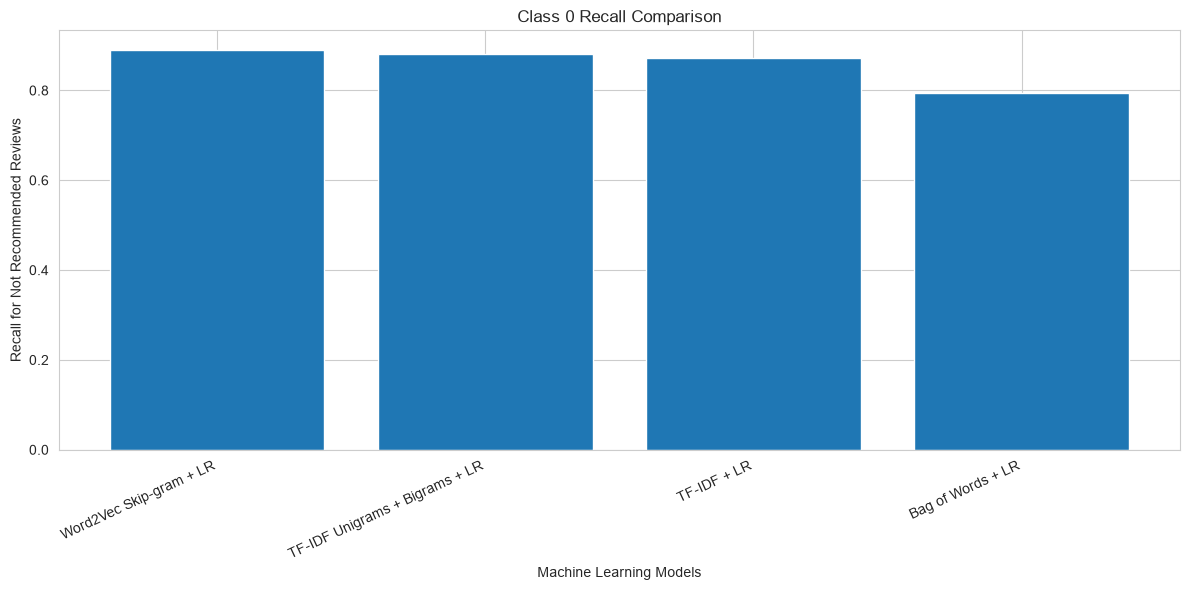

In [210]:
plt.figure(figsize=(12, 6))

plt.bar(
    results_df["Model"],
    results_df["Class 0 Recall"]
)

plt.title("Class 0 Recall Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Recall for Not Recommended Reviews")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()

plt.show()

## Plot ROC curves

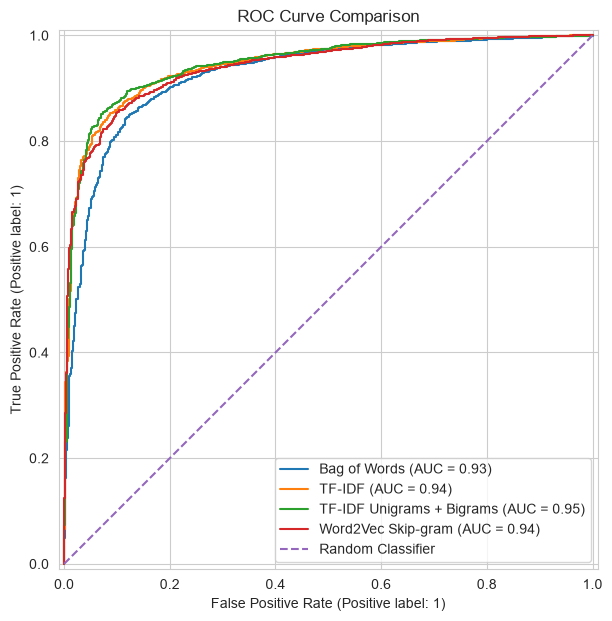

In [211]:
fig, ax = plt.subplots(figsize=(9, 7))

RocCurveDisplay.from_predictions(
    y_test,
    bow_probabilities,
    name="Bag of Words",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test,
    tfidf_probabilities,
    name="TF-IDF",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test,
    bigram_probabilities,
    name="TF-IDF Unigrams + Bigrams",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test,
    w2v_probabilities,
    name="Word2Vec Skip-gram",
    ax=ax
)

ax.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
ax.set_title("ROC Curve Comparison")
ax.legend()
plt.show()

## Select the best model

In [212]:
best_model_name = results_df.iloc[0]["Model"]

print("Best model based on Class 0 Recall:")
print(best_model_name)

print("\nBest model results:")
display(results_df.iloc[[0]].round(4))

Best model based on Class 0 Recall:
Word2Vec Skip-gram + LR

Best model results:


,Model,Accuracy,Class 0 Precision,Class 0 Recall,Class 0 F1,ROC-AUC
0,Word2Vec Skip-gram + LR,0.8651,0.5837,0.889,0.7047,0.9413


## Generate classification report

In [213]:
predictions_by_model = {
    "Bag of Words + LR": bow_predictions,
    "TF-IDF + LR": tfidf_predictions,
    "TF-IDF Unigrams + Bigrams + LR": bigram_predictions,
    "Word2Vec Skip-gram + LR": w2v_predictions
}

best_predictions = predictions_by_model[best_model_name]

print("CLASSIFICATION REPORT")
print("---------------------")

print(
    classification_report(
        y_test,
        best_predictions,
        target_names=["Not Recommended", "Recommended"],
        zero_division=0
    )
)

CLASSIFICATION REPORT
---------------------
                 precision    recall  f1-score   support

Not Recommended       0.58      0.89      0.70       820
    Recommended       0.97      0.86      0.91      3709

       accuracy                           0.87      4529
      macro avg       0.78      0.87      0.81      4529
   weighted avg       0.90      0.87      0.87      4529



## Plot the best model confusion matrix

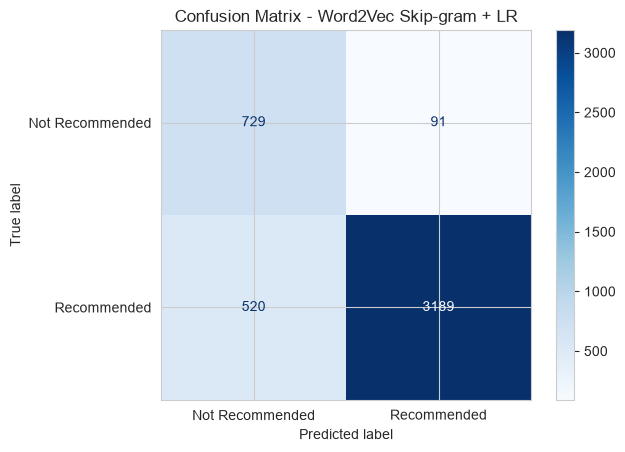

In [214]:
cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Recommended", "Recommended"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title(f"Confusion Matrix - {best_model_name}")
plt.show()

## Compare prediction thresholds

In [215]:
probabilities_by_model = {
    "Bag of Words + LR": bow_probabilities,
    "TF-IDF + LR": tfidf_probabilities,
    "TF-IDF Unigrams + Bigrams + LR": bigram_probabilities,
    "Word2Vec Skip-gram + LR": w2v_probabilities
}

best_probabilities_class1 = probabilities_by_model[best_model_name]

# Convert class 1 probability into class 0 probability
best_probabilities_class0 = 1 - best_probabilities_class1

threshold_results = []

for threshold in [0.3, 0.5, 0.7]:

    threshold_predictions = (
        best_probabilities_class0 >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Class 0 Precision": precision_score(
            y_test,
            threshold_predictions,
            pos_label=0,
            zero_division=0
        ),
        "Class 0 Recall": recall_score(
            y_test,
            threshold_predictions,
            pos_label=0,
            zero_division=0
        ),
        "Class 0 F1": f1_score(
            y_test,
            threshold_predictions,
            pos_label=0,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Class 0 Precision,Class 0 Recall,Class 0 F1
0,0.3,0.0118,0.0415,0.0184
1,0.5,0.0277,0.1110,0.0444
2,0.7,0.0566,0.2524,0.0925


## Find the strongest TF-IDF words

In [216]:
tfidf_candidates = {
    "TF-IDF + LR": tfidf_pipeline,
    "TF-IDF Unigrams + Bigrams + LR": tfidf_bigram_pipeline
}

tfidf_candidate_recalls = {
    "TF-IDF + LR": recall_score(
        y_test, tfidf_predictions, pos_label=0, zero_division=0
    ),
    "TF-IDF Unigrams + Bigrams + LR": recall_score(
        y_test, bigram_predictions, pos_label=0, zero_division=0
    )
}

best_tfidf_name = max(
    tfidf_candidate_recalls,
    key=tfidf_candidate_recalls.get
)

best_tfidf_pipeline = tfidf_candidates[best_tfidf_name]

print("Best TF-IDF model:", best_tfidf_name)
print("Class 0 Recall:", round(
    tfidf_candidate_recalls[best_tfidf_name], 4
))

Best TF-IDF model: TF-IDF Unigrams + Bigrams + LR
Class 0 Recall: 0.8817


## Display words that influence predictions

In [217]:
best_vectorizer = best_tfidf_pipeline.named_steps["vectorizer"]
best_classifier = best_tfidf_pipeline.named_steps["classifier"]

feature_names = best_vectorizer.get_feature_names_out()
coefficients = best_classifier.coef_[0]

feature_importance = pd.DataFrame({
    "Word": feature_names,
    "Coefficient": coefficients
})

# Negative coefficients push predictions toward class 0
# Positive coefficients push predictions toward class 1

strongest_not_recommended = (
    feature_importance
    .sort_values("Coefficient")
    .head(8)
)

strongest_recommended = (
    feature_importance
    .sort_values("Coefficient", ascending=False)
    .head(8)
)

print("Words associated with NOT RECOMMENDED:")
display(strongest_not_recommended)

print("Words associated with RECOMMENDED:")
display(strongest_recommended)

Words associated with NOT RECOMMENDED:


,Word,Coefficient
988,disappointed,-6.461245
4672,wanted love,-5.680217
2786,not flattering,-5.208958
2740,not,-4.919261
3499,returning,-4.750649
4569,unflattering,-4.653974
3497,returned,-4.385891
3233,poor,-3.869562


Words associated with RECOMMENDED:


,Word,Coefficient
2345,love,7.112133
3101,perfect,5.678068
1723,great,5.486800
687,comfortable,4.465477
4574,unique,4.404668
1488,flattering,3.939797
3996,soft,3.885191
2219,little,3.628215


## Plot the strongest words

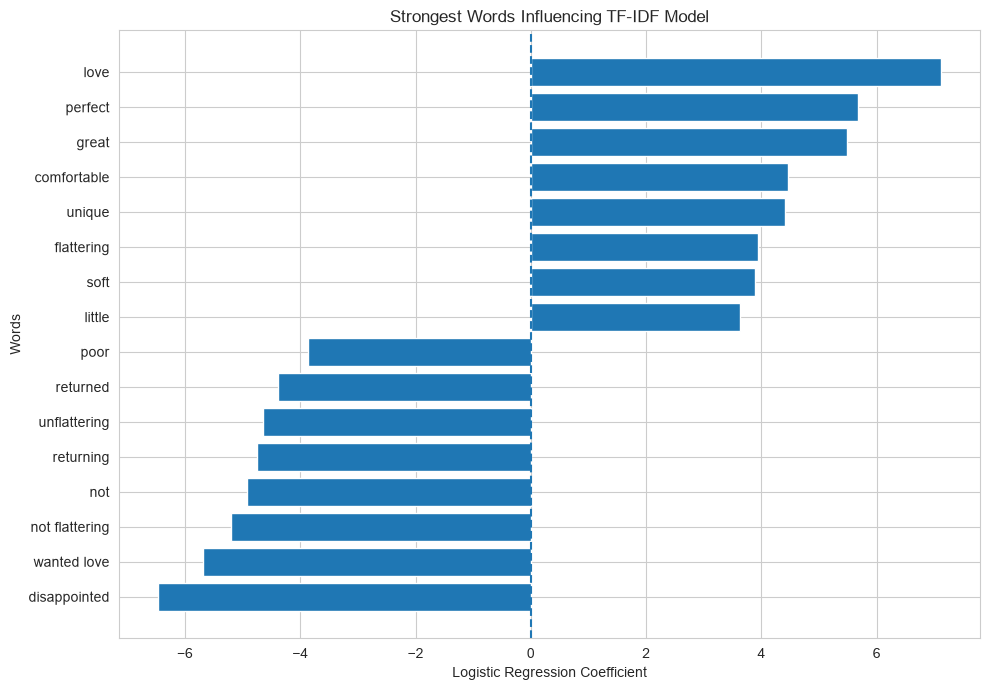

In [218]:
plot_features = pd.concat([
    strongest_not_recommended,
    strongest_recommended
]).sort_values("Coefficient")

plt.figure(figsize=(10, 7))

plt.barh(
    plot_features["Word"],
    plot_features["Coefficient"]
)

plt.axvline(0, linestyle="--")
plt.title("Strongest Words Influencing TF-IDF Model")
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Words")
plt.tight_layout()

plt.show()

## Inspect five incorrect predictions

In [219]:
test_results = pd.DataFrame({
    "Actual": np.asarray(y_test),
    "Predicted": np.asarray(best_predictions),
    "Review": np.asarray(X_test_clean)
})

incorrect_predictions = test_results[
    test_results["Actual"] != test_results["Predicted"]
]

print("Total incorrect predictions:", len(incorrect_predictions))

display(
    incorrect_predictions.head(5)
)

Total incorrect predictions: 611


,Actual,Predicted,Review
6,1,0,pretty thin shirt fit nice classic cut would i...
11,1,0,beautiful skirt run small ordered skirt usual ...
22,0,1,love usually wear review helpful looking pic s...
28,1,0,cosiest coat agree reviewer not flattering coa...
54,1,0,two one high quality swimsuit worn inside easy...


## Save the best text-classification pipeline

In [220]:
best_pipeline = best_tfidf_pipeline

os.makedirs("models", exist_ok=True)

model_path = os.path.join(
    "models",
    "recommend_pipeline.pkl"
)

joblib.dump(best_pipeline, model_path)

print("Best text pipeline saved successfully!")
print("Saved location:", model_path)

Best text pipeline saved successfully!
Saved location: models\recommend_pipeline.pkl


## Load the saved pipeline

In [221]:
loaded_pipeline = joblib.load(
    "models/recommend_pipeline.pkl"
)

print("Pipeline loaded successfully!")
print(loaded_pipeline)

Pipeline loaded successfully!
Pipeline(steps=[('vectorizer',
                 TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])


## Test the model with five new reviews

In [222]:
new_reviews = [
    "This dress is beautiful and comfortable. I love the quality.",
    "The material is very poor and the size is completely wrong.",
    "I am happy with this product and would recommend it.",
    "The fabric is cheap and the stitching is terrible.",
    "The product looks nice but the fitting is not good."
]

cleaned_new_reviews = [
    clean_text(review)
    for review in new_reviews
]

new_predictions = loaded_pipeline.predict(
    cleaned_new_reviews
)

new_probabilities = loaded_pipeline.predict_proba(
    cleaned_new_reviews
)

for i, review in enumerate(new_reviews):

    prediction = new_predictions[i]

    probability_not_recommended = new_probabilities[i][
        list(loaded_pipeline.classes_).index(0)
    ]

    result = (
        "Not Recommended"
        if prediction == 0
        else "Recommended"
    )

    print("Review:", review)
    print("Prediction:", result)
    print(
        "Probability of Not Recommended:",
        round(probability_not_recommended, 4)
    )
    print("-" * 70)

Review: This dress is beautiful and comfortable. I love the quality.
Prediction: Recommended
Probability of Not Recommended: 0.086
----------------------------------------------------------------------
Review: The material is very poor and the size is completely wrong.
Prediction: Not Recommended
Probability of Not Recommended: 0.9902
----------------------------------------------------------------------
Review: I am happy with this product and would recommend it.
Prediction: Recommended
Probability of Not Recommended: 0.1464
----------------------------------------------------------------------
Review: The fabric is cheap and the stitching is terrible.
Prediction: Not Recommended
Probability of Not Recommended: 0.9856
----------------------------------------------------------------------
Review: The product looks nice but the fitting is not good.
Prediction: Not Recommended
Probability of Not Recommended: 0.7657
----------------------------------------------------------------------


# Step 5 — Rule-Based Sentiment, VADER Sentiment, and POS Tagging
## Part A — Rule-Based Sentiment Analysis
##  Import required libraries
## Import libraries and download VADER resources

In [223]:
import nltk
import re
from collections import Counter

from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    precision_score
)

nltk.download("vader_lexicon")
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("averaged_perceptron_tagger")
nltk.download("averaged_perceptron_tagger_eng")

print("Step 5 libraries and NLTK resources are ready!")

Step 5 libraries and NLTK resources are ready!


[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


## Prepare the first 1,000 training and test reviews

In [224]:
X_train_raw = list(X_train)
X_test_raw = list(X_test)

y_train_array = np.asarray(y_train)
y_test_array = np.asarray(y_test)

train_size = min(1000, len(X_train_raw))
test_size = min(1000, len(X_test_raw))

train_reviews_1000 = X_train_raw[:train_size]
train_labels_1000 = y_train_array[:train_size]

test_reviews_1000 = X_test_raw[:test_size]
test_labels_1000 = y_test_array[:test_size]

print("Training reviews:", len(train_reviews_1000))
print("Test reviews:", len(test_reviews_1000))

Training reviews: 1000
Test reviews: 1000


#  Part A — Heuristic rule-based sentiment analysis
# Create 15 warning words or phrases

In [225]:
warning_phrases = [
    "return",
    "returned",
    "disappointed",
    "too small",
    "too large",
    "poor quality",
    "cheap",
    "itchy",
    "uncomfortable",
    "bad quality",
    "poor fit",
    "bad fit",
    "not worth",
    "terrible",
    "defective"
]

print("Total warning phrases:", len(warning_phrases))

for phrase in warning_phrases:
    print("-", phrase)

Total warning phrases: 15
- return
- returned
- disappointed
- too small
- too large
- poor quality
- cheap
- itchy
- uncomfortable
- bad quality
- poor fit
- bad fit
- not worth
- terrible
- defective


## Create the rule-based prediction function

In [226]:
def count_warning_phrases(review):
    review = str(review).lower()

    count = 0

    for phrase in warning_phrases:
        pattern = r"\b" + re.escape(phrase) + r"\b"

        if re.search(pattern, review):
            count += 1

    return count


def heuristic_predict(reviews, minimum_matches=2):
    predictions = []

    for review in reviews:
        warning_count = count_warning_phrases(review)

        if warning_count >= minimum_matches:
            predictions.append(0)
        else:
            predictions.append(1)

    return np.array(predictions)


print("Rule-based prediction functions created!")

Rule-based prediction functions created!


## Compare the two heuristic rules

In [227]:
heuristic_results = []

for minimum_matches in [1, 2]:

    predictions = heuristic_predict(
        test_reviews_1000,
        minimum_matches=minimum_matches
    )

    heuristic_results.append({
        "Minimum Warning Matches": minimum_matches,
        "Accuracy": accuracy_score(
            test_labels_1000, predictions
        ),
        "Recall Class 0": recall_score(
            test_labels_1000,
            predictions,
            pos_label=0,
            zero_division=0
        ),
        "F1 Class 0": f1_score(
            test_labels_1000,
            predictions,
            pos_label=0,
            zero_division=0
        )
    })

heuristic_results_df = pd.DataFrame(heuristic_results)

display(heuristic_results_df.round(4))

,Minimum Warning Matches,Accuracy,Recall Class 0,F1 Class 0
0,1,0.816,0.3077,0.3784
1,2,0.824,0.0714,0.1287


## Select the better heuristic rule

In [228]:
best_heuristic_row = heuristic_results_df.loc[
    heuristic_results_df["F1 Class 0"].idxmax()
]

best_heuristic_threshold = int(
    best_heuristic_row["Minimum Warning Matches"]
)

heuristic_predictions = heuristic_predict(
    test_reviews_1000,
    minimum_matches=best_heuristic_threshold
)

print("Best heuristic rule:")
print(
    f"Predict not recommended when "
    f"{best_heuristic_threshold} or more warning phrases are found."
)

print("\nAccuracy:", round(
    accuracy_score(test_labels_1000, heuristic_predictions), 4
))

print("Class 0 Recall:", round(
    recall_score(
        test_labels_1000,
        heuristic_predictions,
        pos_label=0,
        zero_division=0
    ), 4
))

print("Class 0 F1:", round(
    f1_score(
        test_labels_1000,
        heuristic_predictions,
        pos_label=0,
        zero_division=0
    ), 4
))

Best heuristic rule:
Predict not recommended when 1 or more warning phrases are found.

Accuracy: 0.816
Class 0 Recall: 0.3077
Class 0 F1: 0.3784


## Check a possible false-positive example

In [229]:
example_review = (
    "I did not return this dress. It is perfect and comfortable."
)

example_count = count_warning_phrases(example_review)

example_prediction = heuristic_predict(
    [example_review],
    minimum_matches=best_heuristic_threshold
)[0]

print("Review:", example_review)
print("Warning phrase matches:", example_count)
print(
    "Prediction:",
    "Not Recommended" if example_prediction == 0
    else "Recommended"
)

Review: I did not return this dress. It is perfect and comfortable.
Warning phrase matches: 1
Prediction: Not Recommended


# Part B — VADER sentiment analysis
## Initialize VADER

In [230]:
sia = SentimentIntensityAnalyzer()

print("VADER initialized successfully!")

sample_review = train_reviews_1000[0]

print("\nSample review:")
print(sample_review)

print("\nVADER sentiment scores:")
print(sia.polarity_scores(str(sample_review)))

VADER initialized successfully!

Sample review:
Perfect fall jacket Loved this from the minute i saw it in an email. i got the blue grey in a medium. i'm 5'4", 140. it's a little roomy but will be nice over sweaters too. i love the cropped length. really well made.

VADER sentiment scores:
{'neg': 0.0, 'neu': 0.641, 'pos': 0.359, 'compound': 0.9551}


## Calculate VADER compound scores for training reviews

In [231]:
train_vader_scores = np.array([
    sia.polarity_scores(str(review))["compound"]
    for review in train_reviews_1000
])

print("Training VADER scores calculated!")
print("Number of scores:", len(train_vader_scores))
print("First 10 scores:", train_vader_scores[:10])

Training VADER scores calculated!
Number of scores: 1000
First 10 scores: [0.9551 0.8718 0.9731 0.9485 0.8274 0.9813 0.9773 0.9658 0.7423 0.9839]


## Choose the best VADER threshold using training data

In [232]:
vader_threshold_results = []

for threshold in [0, 0.2, 0.4]:

    predictions = (
        train_vader_scores < threshold
    ).astype(int)

    vader_threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            train_labels_1000, predictions
        ),
        "Recall Class 0": recall_score(
            train_labels_1000,
            predictions,
            pos_label=0,
            zero_division=0
        ),
        "F1 Class 0": f1_score(
            train_labels_1000,
            predictions,
            pos_label=0,
            zero_division=0
        )
    })

vader_threshold_df = pd.DataFrame(vader_threshold_results)

display(vader_threshold_df.round(4))

,Threshold,Accuracy,Recall Class 0,F1 Class 0
0,0.0,0.163,0.7947,0.2651
1,0.2,0.153,0.6947,0.2376
2,0.4,0.153,0.6474,0.2251


## Select the best VADER threshold

In [233]:
best_vader_row = vader_threshold_df.loc[
    vader_threshold_df["F1 Class 0"].idxmax()
]

best_vader_threshold = float(
    best_vader_row["Threshold"]
)

print("Best VADER threshold:", best_vader_threshold)
print(
    "Training Class 0 F1:",
    round(best_vader_row["F1 Class 0"], 4)
)

Best VADER threshold: 0.0
Training Class 0 F1: 0.2651


## Apply VADER to the first 1,000 test reviews

In [234]:
test_vader_scores = np.array([
    sia.polarity_scores(str(review))["compound"]
    for review in test_reviews_1000
])

vader_predictions = (
    test_vader_scores < best_vader_threshold
).astype(int)

vader_accuracy = accuracy_score(
    test_labels_1000,
    vader_predictions
)

vader_recall = recall_score(
    test_labels_1000,
    vader_predictions,
    pos_label=0,
    zero_division=0
)

vader_f1 = f1_score(
    test_labels_1000,
    vader_predictions,
    pos_label=0,
    zero_division=0
)

print("VADER TEST RESULTS")
print("------------------")
print("Accuracy:", round(vader_accuracy, 4))
print("Class 0 Recall:", round(vader_recall, 4))
print("Class 0 F1:", round(vader_f1, 4))

VADER TEST RESULTS
------------------
Accuracy: 0.15
Class 0 Recall: 0.7582
Class 0 F1: 0.2451


# Part C — Machine-learning approach
## Evaluate the saved ML pipeline on the same test reviews

In [235]:
# Clean the raw test reviews using the same cleaning function
test_reviews_1000_clean = [
    clean_text(str(review))
    for review in test_reviews_1000
]

# Load the saved model if it is not already loaded
loaded_pipeline = joblib.load(
    "models/recommend_pipeline.pkl"
)

ml_predictions = loaded_pipeline.predict(
    test_reviews_1000_clean
)

ml_accuracy = accuracy_score(
    test_labels_1000,
    ml_predictions
)

ml_recall = recall_score(
    test_labels_1000,
    ml_predictions,
    pos_label=0,
    zero_division=0
)

ml_f1 = f1_score(
    test_labels_1000,
    ml_predictions,
    pos_label=0,
    zero_division=0
)

print("MACHINE LEARNING TEST RESULTS")
print("-----------------------------")
print("Accuracy:", round(ml_accuracy, 4))
print("Class 0 Recall:", round(ml_recall, 4))
print("Class 0 F1:", round(ml_f1, 4))

MACHINE LEARNING TEST RESULTS
-----------------------------
Accuracy: 0.889
Class 0 Recall: 0.8846
Class 0 F1: 0.7436


## Compare all three approaches

In [236]:
comparison_results = [
    {
        "Approach": "Heuristic Rule-Based",
        "Needs Training Data?": "No",
        "Accuracy": accuracy_score(
            test_labels_1000, heuristic_predictions
        ),
        "Recall Class 0": recall_score(
            test_labels_1000,
            heuristic_predictions,
            pos_label=0,
            zero_division=0
        ),
        "F1 Class 0": f1_score(
            test_labels_1000,
            heuristic_predictions,
            pos_label=0,
            zero_division=0
        ),
        "Advantage": "Simple and explainable",
        "Disadvantage": "Misses context and negation"
    },
    {
        "Approach": "VADER",
        "Needs Training Data?": "No",
        "Accuracy": vader_accuracy,
        "Recall Class 0": vader_recall,
        "F1 Class 0": vader_f1,
        "Advantage": "Pre-built sentiment tool",
        "Disadvantage": "May miss fashion-specific meaning"
    },
    {
        "Approach": "Machine Learning",
        "Needs Training Data?": "Yes",
        "Accuracy": ml_accuracy,
        "Recall Class 0": ml_recall,
        "F1 Class 0": ml_f1,
        "Advantage": "Learns patterns from reviews",
        "Disadvantage": "Requires labelled training data"
    }
]

approach_comparison_df = pd.DataFrame(comparison_results)

display(
    approach_comparison_df.round(4)
)

,Approach,Needs Training Data?,Accuracy,Recall Class 0,F1 Class 0,Advantage,Disadvantage
0,Heuristic Rule-Based,No,0.816,0.3077,0.3784,Simple and explainable,Misses context and negation
1,VADER,No,0.150,0.7582,0.2451,Pre-built sentiment tool,May miss fashion-specific meaning
2,Machine Learning,Yes,0.889,0.8846,0.7436,Learns patterns from reviews,Requires labelled training data


## Plot the three approaches

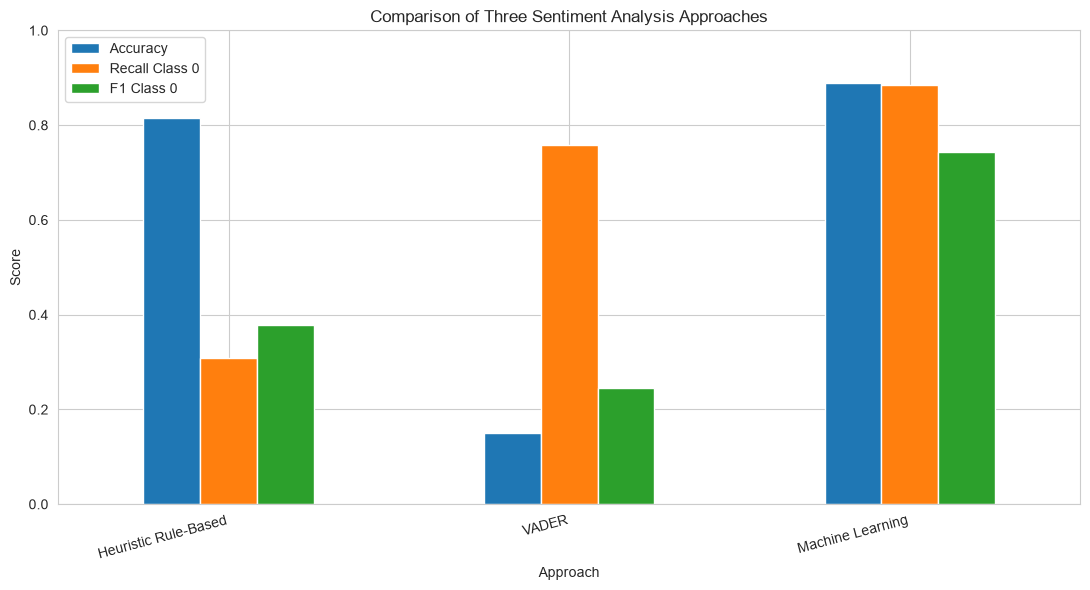

In [237]:
comparison_plot = approach_comparison_df.set_index(
    "Approach"
)[["Accuracy", "Recall Class 0", "F1 Class 0"]]

comparison_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Comparison of Three Sentiment Analysis Approaches")
plt.ylabel("Score")
plt.xlabel("Approach")
plt.xticks(rotation=15, ha="right")
plt.ylim(0, 1)
plt.legend(loc="best")
plt.tight_layout()

plt.show()

# Part D — Part-of-Speech (POS) tagging
POS tagging identifies the grammatical role of each word, such as noun, verb, adjective, or adverb.
## Write five fashion reviews and perform POS tagging

In [238]:
fashion_reviews = [
    "This dress has beautiful fabric and excellent quality.",
    "The fitting is poor and the material feels uncomfortable.",
    "I love this stylish shirt and its soft texture.",
    "The product looks expensive but feels very cheap.",
    "The comfortable design makes this dress perfect."
]

pos_results = []

for review in fashion_reviews:

    tokens = nltk.word_tokenize(review)
    tagged_words = nltk.pos_tag(tokens)

    for word, tag in tagged_words:
        pos_results.append({
            "Review": review,
            "Word": word,
            "POS Tag": tag
        })

pos_results_df = pd.DataFrame(pos_results)

display(pos_results_df)

,Review,Word,POS Tag
0,This dress has beautiful fabric and excellent ...,This,DT
1,This dress has beautiful fabric and excellent ...,dress,NN
2,This dress has beautiful fabric and excellent ...,has,VBZ
3,This dress has beautiful fabric and excellent ...,beautiful,VBN
4,This dress has beautiful fabric and excellent ...,fabric,JJ
5,This dress has beautiful fabric and excellent ...,and,CC
6,This dress has beautiful fabric and excellent ...,excellent,JJ
7,This dress has beautiful fabric and excellent ...,quality,NN
8,This dress has beautiful fabric and excellent ...,.,.
9,The fitting is poor and the material feels unc...,The,DT


### POS Tag – Meaning and Examples

| POS Tag | Meaning | Example |
|:---:|---|---|
| NN | Singular noun | dress |
| NNS | Plural noun | dresses |
| VB | Base form of verb | fit |
| VBD | Past-tense verb | returned |
| JJ | Adjective | beautiful |
| RB | Adverb | very |
| PRP | Personal pronoun | I, she |
| IN | Preposition or subordinating conjunction | in, with |

## Select 1,000 not-recommended training reviews

In [239]:
negative_training_reviews = [
    str(review).lower()
    for review, label in zip(X_train_raw, y_train_array)
    if label == 0
][:1000]

print(
    "Not-recommended training reviews selected:",
    len(negative_training_reviews)
)

print("\nExample:")
print(negative_training_reviews[0])

Not-recommended training reviews selected: 1000

Example:
going back... i purchased this dress in the green, and while the print and material were lovely, the extra folds in the neckline made the dress look frumpy up top. the billowly bottom made it look like a bag. i am 5ft, 36d and 29" waist and the size 2 fit, which makes me think this runs large! i'll be returning this dress.


## Extract adjective + noun complaint phrases

In [240]:
complaint_phrases = []

for review in negative_training_reviews:

    tokens = nltk.word_tokenize(review)
    tagged_words = nltk.pos_tag(tokens)

    for i in range(len(tagged_words) - 1):

        word1, tag1 = tagged_words[i]
        word2, tag2 = tagged_words[i + 1]

        if tag1 == "JJ" and tag2 in ["NN", "NNS"]:

            phrase = word1.lower() + " " + word2.lower()

            complaint_phrases.append(phrase)

print("Total complaint phrases found:", len(complaint_phrases))
print("\nFirst 20 phrases:")
print(complaint_phrases[:20])

Total complaint phrases found: 2587

First 20 phrases:
['extra folds', 'yellow pair', 'first time', 'super cute', 'small stains', 'untreatable stains', 'second pair', 'glad i', 'flattering pieces', 'huge i', 'sturdy beautiful', 'large picture', 'bottom hem', 'slim hips', 'disappointed i', 'top sweater', 'awkward fit', 'stiff fabric', 'whole front', 'big drawback']


## Find the 10 most frequent complaint phrases

In [241]:
phrase_counts = Counter(complaint_phrases)

top_10_phrases = phrase_counts.most_common(10)

top_phrases_df = pd.DataFrame(
    top_10_phrases,
    columns=["Complaint Phrase", "Frequency"]
)

display(top_phrases_df)

,Complaint Phrase,Frequency
0,other reviewers,26
1,poor quality,23
2,much fabric,20
3,usual size,16
4,other reviews,16
5,high hopes,13
6,good quality,12
7,first time,11
8,super cute,10
9,real life,10


## Plot the top 10 complaint phrases

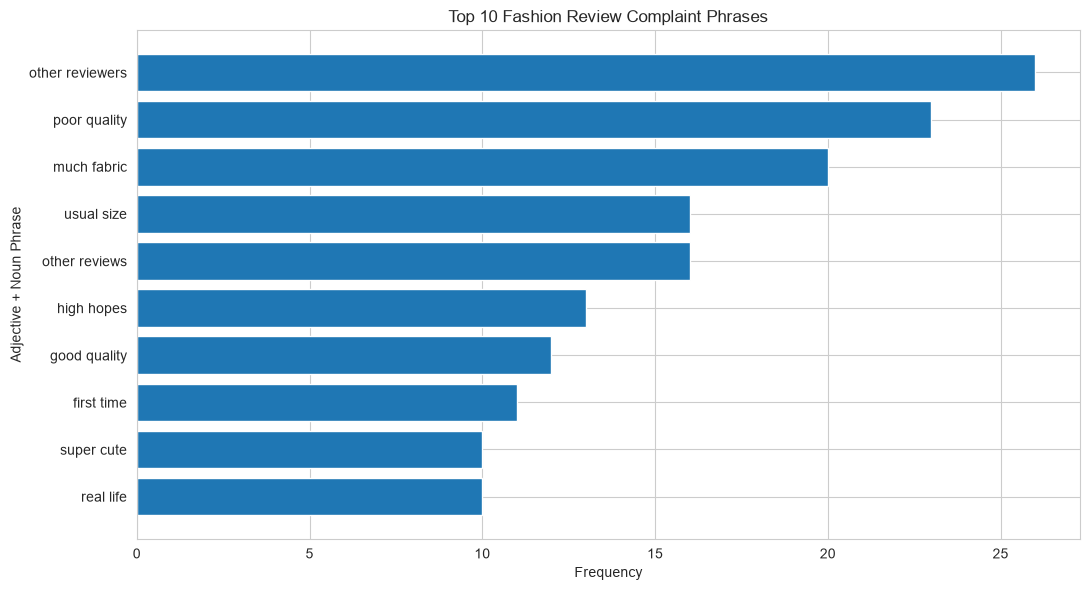

In [242]:
plt.figure(figsize=(11, 6))

plt.barh(
    top_phrases_df["Complaint Phrase"][::-1],
    top_phrases_df["Frequency"][::-1]
)

plt.title("Top 10 Fashion Review Complaint Phrases")
plt.xlabel("Frequency")
plt.ylabel("Adjective + Noun Phrase")
plt.tight_layout()

plt.show()

## Find the department with the highest not-recommended rate

In [243]:
department_complaint_rates = (
    df.groupby("Department Name")["Recommended IND"]
    .apply(lambda values: (values == 0).mean())
    .sort_values(ascending=False)
)

print("Not-recommended rate by department:")
display(
    department_complaint_rates.reset_index(
        name="Not Recommended Rate"
    ).round(4)
)

highest_complaint_department = department_complaint_rates.idxmax()

highest_complaint_rate = department_complaint_rates.max()

print("\nDepartment with highest not-recommended rate:")
print(highest_complaint_department)

print(
    "Not-recommended rate:",
    round(highest_complaint_rate * 100, 2),
    "%"
)

Not-recommended rate by department:


,Department Name,Not Recommended Rate
0,Trend,0.2542
1,Dresses,0.1948
2,Tops,0.1893
3,Jackets,0.1667
4,Intimate,0.1537
5,Bottoms,0.1505



Department with highest not-recommended rate:
Trend
Not-recommended rate: 25.42 %


## Review the complaint phrases and department together

In [244]:
print("Highest complaint department:", highest_complaint_department)

print("\nTop complaint phrases:")
display(top_phrases_df)

print(
    "\nThe quality team should investigate the most frequent complaint "
    "phrases and check whether those issues are concentrated in the "
    "department with the highest not-recommended rate."
)

Highest complaint department: Trend

Top complaint phrases:


,Complaint Phrase,Frequency
0,other reviewers,26
1,poor quality,23
2,much fabric,20
3,usual size,16
4,other reviews,16
5,high hopes,13
6,good quality,12
7,first time,11
8,super cute,10
9,real life,10



The quality team should investigate the most frequent complaint phrases and check whether those issues are concentrated in the department with the highest not-recommended rate.


# Part E — Interpret your results
## Print the best approach

In [245]:
best_approach = approach_comparison_df.loc[
    approach_comparison_df["F1 Class 0"].idxmax()
]

print("BEST APPROACH")
print("-------------")
print("Approach:", best_approach["Approach"])
print("Accuracy:", round(best_approach["Accuracy"], 4))
print("Class 0 Recall:", round(best_approach["Recall Class 0"], 4))
print("Class 0 F1:", round(best_approach["F1 Class 0"], 4))

BEST APPROACH
-------------
Approach: Machine Learning
Accuracy: 0.889
Class 0 Recall: 0.8846
Class 0 F1: 0.7436


Comparison of sentiment-analysis approaches
- Rule-based analysis is useful when a business needs a simple system based on predefined complaint keywords. It is easy to explain but may incorrectly identify reviews because it does not fully understand context or negation.
- VADER is useful when we need a ready-made sentiment tool without collecting labelled training data. However, general sentiment scoring may not understand fashion-specific complaints.
- Machine learning is useful when we have labelled customer reviews and want the system to learn patterns from actual customer feedback. It requires training data and model maintenance.
- A rule-based approach is generally the easiest to explain to a business manager, while the machine-learning approach may provide better results if its evaluation supports that conclusion.

How does POS tagging work?
1. POS tagging identifies the grammatical category of each word in a sentence.
2. It can be difficult because a word can have different grammatical roles depending on its context. For example, fit is a noun in "a perfect fit" but a verb in "it does not fit".
3. A rule-based tagger uses predefined grammatical rules to assign tags.
4. A statistical tagger learns patterns from previously tagged text.
5. NLTK's default English POS tagger (nltk.pos_tag) uses a trained statistical Averaged Perceptron tagger.

# Step 6 – Build Streamlit App
## Install Streamlit

In [246]:
%pip install streamlit joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Create text_utils.py

In [247]:
%%writefile text_utils.py

import re
import nltk

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer


# Download required NLTK resources
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)


# Initialize NLP tools
stop_words = set(stopwords.words("english"))

# Preserve important negative words
stop_words.discard("not")
stop_words.discard("no")
stop_words.discard("nor")

lemmatizer = WordNetLemmatizer()


# Text cleaning function
def clean_text(text):

    if not isinstance(text, str):
        text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Remove numbers
    text = re.sub(r"\d+", " ", text)

    # Remove special characters
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Tokenization
    tokens = word_tokenize(text)

    # Remove stopwords and lemmatize
    cleaned_tokens = []

    for word in tokens:

        if word not in stop_words:

            lemma = lemmatizer.lemmatize(word)

            cleaned_tokens.append(lemma)

    return " ".join(cleaned_tokens)

Overwriting text_utils.py


## Check required files

In [248]:
import os

print("Current directory:", os.getcwd())

print("\nRequired files:")

files = [
    "text_utils.py",
    "models/recommend_pipeline.pkl"
]

for file in files:
    if os.path.exists(file):
        print(f"✅ {file} found")
    else:
        print(f"❌ {file} not found")

Current directory: d:\rnw\NLP\NLP_Practical_Exam_Set_C

Required files:
✅ text_utils.py found
✅ models/recommend_pipeline.pkl found


## Create the Streamlit application

In [249]:
%%writefile app.py

import streamlit as st
import joblib
import re
import os

from pathlib import Path
from text_utils import clean_text


# ==========================================
# PAGE CONFIGURATION
# ==========================================

st.set_page_config(
    page_title="Fashion Review Analytics",
    page_icon="👗",
    layout="wide"
)


# ==========================================
# LOAD TRAINED MODEL
# ==========================================

BASE_DIR = Path(__file__).resolve().parent

MODEL_PATH = BASE_DIR / "models" / "recommend_pipeline.pkl"


@st.cache_resource
def load_model():

    model = joblib.load(MODEL_PATH)

    return model


model = load_model()


# ==========================================
# APPLICATION HEADER
# ==========================================

st.title("👗 Fashion Review Analytics")

st.write(
    "Analyze customer fashion reviews using "
    "Natural Language Processing and Machine Learning."
)

st.divider()


# ==========================================
# SIDEBAR
# ==========================================

st.sidebar.title("📌 About This Project")

st.sidebar.write(
    """
    This application predicts whether a customer
    would recommend a fashion product based on
    their written review.

    **Technologies:**
    - Python
    - NLP
    - TF-IDF
    - Logistic Regression
    - Streamlit
    """
)

st.sidebar.subheader("📝 Example Reviews")

st.sidebar.markdown(
    """
    **Example 1 – Positive**

    I absolutely love this dress. The quality
    is excellent and it fits perfectly.

    ---

    **Example 2 – Negative**

    The fabric quality is poor and the dress
    is uncomfortable.

    ---

    **Example 3 – Mixed**

    The design is beautiful but the material
    is not worth the price.
    """
)


# ==========================================
# USER INPUT
# ==========================================

st.subheader("Enter Customer Review")

title_input = st.text_input(
    "Product Title",
    placeholder="Example: Beautiful Summer Dress"
)

review_text = st.text_area(
    "Customer Review",
    placeholder="Write your fashion product review here...",
    height=150
)


# ==========================================
# ANALYZE BUTTON
# ==========================================

if st.button("🔍 Analyze Review", use_container_width=True):

    if not review_text.strip():

        st.warning("Please enter a review.")

    else:

        # Combine title and review
        full_text = str(title_input) + " " + str(review_text)

        # Clean input text
        cleaned_review = clean_text(full_text)

        # Convert into list for prediction
        input_data = [cleaned_review]

        # Predict class
        prediction = model.predict(input_data)[0]

        # Get probabilities
        probabilities = model.predict_proba(input_data)[0]

        # Identify class indexes
        classes = list(model.classes_)

        recommend_index = classes.index(1)
        not_recommend_index = classes.index(0)

        recommend_probability = probabilities[recommend_index]
        not_recommend_probability = probabilities[not_recommend_index]


        # ==================================
        # PREDICTION RESULT
        # ==================================

        st.divider()

        st.subheader("📊 Prediction Result")

        if prediction == 1:

            st.success("Customer would recommend")

        else:

            st.error("Customer would NOT recommend")


        # ==================================
        # PROBABILITY
        # ==================================

        st.subheader("Recommendation Probability")

        percentage = recommend_probability * 100

        st.metric(
            label="Probability of Recommendation",
            value=f"{percentage:.2f}%"
        )

        st.progress(float(recommend_probability))


        # ==================================
        # QUALITY WARNING
        # ==================================

        if not_recommend_probability > 0.5:

            st.warning(
                "⚠️ Send to quality team: "
                "The customer may not recommend this product."
            )


        # ==================================
        # REVIEW STATISTICS
        # ==================================

        st.divider()

        st.subheader("📝 Review Statistics")

        word_count = len(
            re.findall(r"\b\w+\b", review_text)
        )

        exclamation_count = review_text.count("!")

        capital_words = re.findall(
            r"\b[A-Z]{2,}\b",
            review_text
        )

        col1, col2, col3 = st.columns(3)

        col1.metric("Word Count", word_count)

        col2.metric(
            "Exclamation Marks",
            exclamation_count
        )

        col3.metric(
            "ALL-CAPS Words",
            len(capital_words)
        )


        # ==================================
        # PROBABILITY DETAILS
        # ==================================

        st.divider()

        st.subheader("Prediction Confidence")

        col1, col2 = st.columns(2)

        col1.metric(
            "Recommend",
            f"{recommend_probability * 100:.2f}%"
        )

        col2.metric(
            "Not Recommend",
            f"{not_recommend_probability * 100:.2f}%"
        )


# ==========================================
# FOOTER
# ==========================================

st.divider()

st.caption(
    "NLP Practical Exam – Set C | "
    "Fashion Review Analytics"
)

Overwriting app.py


 ## Check required files

In [250]:
import os

if os.path.exists("app.py"):
    print("✅ app.py created successfully")
else:
    print("❌ app.py was not created")

✅ app.py created successfully


## Run the Streamlit application

In [251]:
!streamlit run app.py

^C


In [252]:
import pandas as pd
from IPython.display import display

final_results = results_df.copy()

baseline = pd.DataFrame([{
    "Model": "Baseline - Always Recommends",
    "Accuracy": 0.8189,
    "Class 0 Precision": 0.0000,
    "Class 0 Recall": 0.0000,
    "Class 0 F1": 0.0000,
    "ROC-AUC": 0.5000
}])

final_results = pd.concat(
    [baseline, final_results],
    ignore_index=True
)

final_results = final_results.round(4)

display(final_results)

,Model,Accuracy,Class 0 Precision,Class 0 Recall,Class 0 F1,ROC-AUC
0,Baseline - Always Recommends,0.8189,0.0000,0.0000,0.0000,0.5000
1,Word2Vec Skip-gram + LR,0.8651,0.5837,0.8890,0.7047,0.9413
2,TF-IDF Unigrams + Bigrams + LR,0.8881,0.6381,0.8817,0.7404,0.9463
3,TF-IDF + LR,0.8794,0.6185,0.8720,0.7237,0.9441
4,Bag of Words + LR,0.8834,0.6446,0.7939,0.7115,0.9257


In [253]:
import os

os.makedirs("outputs", exist_ok=True)

final_results.to_csv(
    "outputs/step7_classification_results.csv",
    index=False
)

print("Classification results saved successfully!")

Classification results saved successfully!


In [254]:
project_summary = pd.DataFrame([
    {
        "Step": "Step 1 - Data Preprocessing",
        "Dataset / Size": "Women's Clothing Reviews - 22,641 rows",
        "Technique / Library": "Pandas, Regex, Text Cleaning",
        "Key Result": "18.11% Not Recommended"
        
    },
    {
        "Step": "Step 2 - Feature Extraction",
        "Dataset / Size": "18,112 training reviews",
        "Technique / Library": "TF-IDF, Scikit-learn",
        "Key Result": "Vocabulary size: 16 (verify)"
        
    },
    {
        "Step": "Step 3 - Word2Vec",
        "Dataset / Size": "18,112 training reviews",
        "Technique / Library": "Word2Vec Skip-gram",
        "Key Result": "3,910 vocabulary words; 100 dimensions"
        
    },
    {
        "Step": "Step 4 - Classification",
        "Dataset / Size": "18,112 train / 4,529 test",
        "Technique / Library": "Logistic Regression, TF-IDF, Word2Vec, BoW",
        "Key Result": "Best accuracy: 88.81%; ROC-AUC: 0.9463"
       
    },
    {
        "Step": "Step 5 - Heuristic and POS Tagging",
        "Dataset / Size": "Review text samples",
        "Technique / Library": "Warning-word rules, POS tagging",
        "Key Result": "Best heuristic threshold: 1 warning match"
       
    },
    {
        "Step": "Step 6 - Streamlit Deployment",
        "Dataset / Size": "User-entered review",
        "Technique / Library": "Streamlit, Saved ML Pipeline",
        "Key Result": "Enter actual app testing result"
       
    }
])

display(project_summary)

,Step,Dataset / Size,Technique / Library,Key Result
0,Step 1 - Data Preprocessing,"Women's Clothing Reviews - 22,641 rows","Pandas, Regex, Text Cleaning",18.11% Not Recommended
1,Step 2 - Feature Extraction,"18,112 training reviews","TF-IDF, Scikit-learn",Vocabulary size: 16 (verify)
2,Step 3 - Word2Vec,"18,112 training reviews",Word2Vec Skip-gram,"3,910 vocabulary words; 100 dimensions"
3,Step 4 - Classification,"18,112 train / 4,529 test","Logistic Regression, TF-IDF, Word2Vec, BoW",Best accuracy: 88.81%; ROC-AUC: 0.9463
4,Step 5 - Heuristic and POS Tagging,Review text samples,"Warning-word rules, POS tagging",Best heuristic threshold: 1 warning match
5,Step 6 - Streamlit Deployment,User-entered review,"Streamlit, Saved ML Pipeline",Enter actual app testing result


In [255]:
project_summary.to_csv(
    "outputs/step7_project_summary.csv",
    index=False
)

print("Six-step project summary saved!")

Six-step project summary saved!


In [256]:
reflection = [
    "The most challenging step was preprocessing and preparing review text for machine learning because text data required cleaning and transformation.",

    "The always-recommends baseline achieved 81.89% accuracy but had 0% recall for Class 0. This shows that accuracy alone is not sufficient for an imbalanced classification problem.",

    "Data leakage was prevented by fitting feature extraction and model training only on training data, then evaluating on the separate test data.",

    "TF-IDF unigrams and bigrams performed best overall, achieving 88.81% accuracy and 0.9463 ROC-AUC.",

    "The heuristic approach with one warning-word match achieved 30.77% Class 0 recall. Requiring two matches reduced recall to 7.14%.",

    "The Word2Vec Skip-gram model achieved 88.90% Class 0 recall, slightly higher than the TF-IDF unigram and bigram model.",

    "Hinglish reviews may require additional preprocessing, language detection, and multilingual NLP techniques.",

    "Future improvements include testing transformer models, improving complaint phrase extraction, tuning classification thresholds, and expanding language support."
]

for i, point in enumerate(reflection, 1):
    print(f"{i}. {point}")

1. The most challenging step was preprocessing and preparing review text for machine learning because text data required cleaning and transformation.
2. The always-recommends baseline achieved 81.89% accuracy but had 0% recall for Class 0. This shows that accuracy alone is not sufficient for an imbalanced classification problem.
3. Data leakage was prevented by fitting feature extraction and model training only on training data, then evaluating on the separate test data.
4. TF-IDF unigrams and bigrams performed best overall, achieving 88.81% accuracy and 0.9463 ROC-AUC.
5. The heuristic approach with one warning-word match achieved 30.77% Class 0 recall. Requiring two matches reduced recall to 7.14%.
6. The Word2Vec Skip-gram model achieved 88.90% Class 0 recall, slightly higher than the TF-IDF unigram and bigram model.
7. Hinglish reviews may require additional preprocessing, language detection, and multilingual NLP techniques.
8. Future improvements include testing transformer models

In [257]:
import joblib

if "best_pipeline" in globals():
    joblib.dump(
        best_pipeline,
        "models/best_nlp_pipeline.pkl"
    )
    print("Best NLP pipeline saved!")
else:
    print("best_pipeline not found. Train your model first.")

Best NLP pipeline saved!


In [258]:
if "skipgram_model" in globals():
    skipgram_model.save("models/word2vec_skipgram.model")
    print("Word2Vec model saved!")
else:
    print("skipgram_model not found.")

Word2Vec model saved!


In [259]:
if "heuristic_results" in globals():
    pd.DataFrame(heuristic_results).to_csv(
        "outputs/heuristic_results.csv",
        index=False
    )

if "pos_results" in globals():
    pd.DataFrame(pos_results).to_csv(
        "outputs/pos_tagging_results.csv",
        index=False
    )

print("Heuristic and POS results saved!")

Heuristic and POS results saved!
